# Milestone 4. Từ lựa chọn mô hình đến thiết kế đánh giá: thực nghiệm Level 2

**Nhóm N02**, học phần Khoa học Phân tích Dữ liệu, Khoa Công nghệ Thông tin, Trường Đại học Khoa học Tự nhiên, ĐHQG-HCM.
Thành viên: Ngô Triệu Gia Gia (25C11037), Trần Duy Khương (25C12004), Nguyễn Hoàng Nhật Quang (25C12033).
Giảng viên phụ trách: TS. Nguyễn Trần Minh Thư.

Notebook này là phần mã nguồn của Level 2 (Prototype Experiment) trong báo cáo Milestone 4. Mục đích của Level 2 là **kiểm chứng tính khả thi** của đề xuất Level 1 (Mục 2 đến Mục 6 của báo cáo) trên Prepared Dataset v1.0, chứ không phải tối ưu một chỉ số. Kết quả tương ứng Mục 7 và Mục 8 của báo cáo.

**Câu hỏi được kiểm chứng**

| AQ | Analytics level | Cách kiểm chứng trong notebook |
|---|---|---|
| AQ4 | Predictive (sàng lọc đồng thời) | So sánh baseline chuyên cần với hồi quy logistic, Random Forest và Gradient Boosting bằng kiểm định chéo lặp |
| AQ7 | Descriptive / Operational | Đường cong recall theo tỷ lệ gắn cờ và bảng precision |
| AQ5 | Explanatory | Hoán vị và ablation theo nhóm tín hiệu, hệ số theo fold, chọn mục khảo sát bằng L1 trong fold |
| AQ6 | Diagnostic / Fairness | Recall và precision theo giới tính, nơi ở tại ngưỡng chung |
| AQ2, AQ3 | Diagnostic | Mô hình logistic hiệu chỉnh so với liên hệ không hiệu chỉnh (chỉ là liên hệ) |

**Nguyên tắc thực nghiệm**

1. **Đăng ký trước.** Tiêu chí thành công S1 đến S5 và quy tắc chọn phương pháp chính được cố định trong tệp kế hoạch có mã băm SHA-256 trước khi huấn luyện. Notebook kiểm tra mã băm và dừng nếu kế hoạch bị sửa.
2. **Chống rò rỉ dữ liệu.** Điền khuyết, chuẩn hóa, chọn đặc trưng và chọn siêu tham số đều nằm trong `Pipeline` và chỉ được fit trên phần huấn luyện của từng fold.
3. **Đánh giá vững.** Kiểm định chéo phân tầng 5 phần lặp 10 lần; khoảng tin cậy 95% bằng bootstrap 2.000 lần; so sánh giữa các mô hình dùng cùng mẫu bootstrap (ghép cặp).
4. **Không điều chỉnh để đạt ngưỡng.** Kết quả không thuận lợi được báo cáo nguyên trạng.

**Cách chạy.** *Runtime → Run all*. Notebook gồm hai phần nối tiếp nhau, **chạy từ tệp dữ liệu gốc**: **Phần A** chuẩn bị dữ liệu (đúng mã của Milestone 3, không có phân tích khám phá), **Phần B** thực nghiệm mô hình và đánh giá. Tổng thời gian khoảng 5 đến 10 phút trên CPU của Colab; bước lâu nhất là kiểm định chéo lặp ở mục B4.


## Đọc trước khi chạy (dành cho giảng viên và các thành viên trong nhóm)

**Cách chạy (3 bước, không cần cài đặt gì):**
1. Mở [Google Colab](https://colab.research.google.com), chọn *File → Upload notebook* và chọn tệp này (hoặc mở tệp từ Google Drive bằng *Open with → Google Colaboratory*).
2. Chọn *Runtime → Run all* (Thời gian chạy → Chạy tất cả).
3. Đợi các ô chạy từ trên xuống dưới, tổng cộng khoảng **5 đến 10 phút**. Không cần tải dữ liệu lên, không cần Google Drive, không cần cài thêm thư viện, **không tốn phí** (Colab miễn phí là đủ, không cần GPU).

**Toàn bộ chương trình nằm trong các ô của notebook này.** Không có tệp `.py` hay thư mục mã nguồn đi kèm; nhóm không cần triển khai trên máy cá nhân.

**Notebook này gồm hai phần:** *Phần A* tạo lại bảng dữ liệu đã chuẩn bị từ tệp gốc (cùng mã với notebook Milestone 3); *Phần B* huấn luyện, đánh giá mô hình và kiểm tra công bằng (Milestone 4). Số mục trong mỗi phần được đánh số riêng (A1, A2... và B1, B2...); khi văn bản nhắc "Mục 2.2" của Phần B thì đó là B2.2.

**Dữ liệu lấy ở đâu?** Tệp dữ liệu gốc `Students_Performance_data_set.xlsx` (187 KB, công khai trên Mendeley Data, DOI 10.17632/dc3797vf3t.1, giấy phép CC BY 4.0 cho phép phân phối lại khi ghi nguồn) được **nhúng ngay trong một ô của notebook** dưới dạng một chuỗi chữ dài (đã nén bằng zlib và mã hóa base64; ô này được thu gọn, bấm để xem). Khi chạy, ô kế tiếp giải chuỗi đó thành tệp Excel trong bộ nhớ tạm của Colab. Vì vậy notebook không tải gì từ internet và vẫn chạy được nếu đường dẫn trên Mendeley thay đổi.

**Mã băm SHA-256 là gì?** Đó là "dấu vân tay" của một tệp: một chuỗi 64 ký tự được tính từ nội dung tệp. Chỉ cần đổi một ký tự trong tệp thì dấu vân tay thay đổi hoàn toàn. Notebook tính lại dấu vân tay của tệp vừa giải nén và so với giá trị đã ghi sẵn; nếu khớp thì đúng là tệp nhóm đã dùng, không bị sửa hay hỏng. Với các tệp kết quả, nếu thư viện Colab khác phiên bản (ví dụ cách ghi số thập phân), dấu vân tay có thể khác dù nội dung không đổi; vì thế ngoài dấu vân tay, notebook còn kiểm tra trực tiếp các con số quan trọng (số dòng, số ca dương, các chỉ số trong báo cáo).

**Tệp tạo ra nằm ở đâu?** Trong thư mục tạm `/content/` của phiên Colab (bấm biểu tượng thư mục ở thanh bên trái để xem hoặc tải về). Thư mục này bị xóa khi phiên kết thúc; chạy lại notebook sẽ tạo lại y hệt.

**Nếu một ô báo lỗi:** chọn *Runtime → Restart session and run all* để chạy lại từ đầu (các ô phụ thuộc nhau theo thứ tự, không nên chạy riêng lẻ ở giữa).

## PHẦN A. Chuẩn bị dữ liệu từ tệp gốc (mã của Milestone 3)

Phần này tái tạo *Prepared Dataset v1.0* bằng đúng các bước đã mô tả ở báo cáo Milestone 3: nạp tệp gốc, chuẩn hóa kiểu dữ liệu, gắn cờ chất lượng, xử lý giá trị khuyết và ngoại lai, tạo biến dẫn xuất, tạo nhãn và chia fold. Mọi bước có ghi nhật ký biến đổi.

### A1. Thiết lập môi trường

#### A1.1. Thư viện và thư mục làm việc

Notebook dùng `pandas`, `numpy`, `scipy`, `scikit-learn` và `matplotlib`, đều có sẵn trên Colab. Cấu trúc thư mục bám theo gói dữ liệu đã nộp: `data/raw` (tệp gốc, chỉ đọc), `data/interim` (bảng trung gian đã chuẩn hóa kiểu), `data/processed` (bảng phân tích), `data/metadata` (từ điển dữ liệu, lineage, nhật ký) và `reports/milestone3` (bảng, hình của EDA).

In [1]:
import hashlib
import json
import platform
import re
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

BASE = Path("/content") if Path("/content").exists() else Path.cwd()
ROOT = BASE / "N02_Milestone4"
raw_path = ROOT / "data" / "raw" / "Students_Performance_data_set.xlsx"
interim = ROOT / "data" / "interim"
processed = ROOT / "data" / "processed"
meta = ROOT / "data" / "metadata"
FIG = ROOT / "reports" / "milestone3" / "figures"
TAB = ROOT / "reports" / "milestone3" / "tables"
for d in (raw_path.parent, interim, processed, meta, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("Thư mục gốc:", ROOT)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scipy 1.16.3 | scikit-learn 1.6.1
Thư mục gốc: /content/N02_Milestone4


#### A1.2. Nạp tệp dữ liệu thô

Tệp `Students_Performance_data_set.xlsx` (Mendeley Data, DOI 10.17632/dc3797vf3t.1, giấy phép CC BY 4.0) được nhúng nguyên văn trong ô dưới đây. Mã băm SHA-256 được kiểm tra khi giải nén và phải trùng với giá trị đã ghi trong nhật ký thu thập của Milestone 2.

In [2]:
#@title Ghi tệp dữ liệu thô nhúng sẵn vào data/raw (bấm để xem mã)
import base64, hashlib, zlib

EMBEDDED_FILES = {
    "data/raw/Students_Performance_data_set.xlsx": {
        "sha256": "04ebaf9f3a047afe96d9bff22dbe65b2a320e6395f230032735495e7e58277cf",
        "data": (
            "..."
        ),
    },
}

for rel, item in EMBEDDED_FILES.items():
    target = ROOT / rel
    target.parent.mkdir(parents=True, exist_ok=True)
    raw = zlib.decompress(base64.b64decode(item["data"]))
    digest = hashlib.sha256(raw).hexdigest()
    assert digest == item["sha256"], f"Tệp {rel} bị hỏng khi giải nén"
    if target.exists():
        target.chmod(0o644)
    target.write_bytes(raw)
    print(f"{rel}: {len(raw):,} byte".replace(",", ".") + f", SHA-256 {digest[:16]}... khớp bản gốc")

data/raw/Students_Performance_data_set.xlsx: 187.253 byte, SHA-256 04ebaf9f3a047afe... khớp bản gốc


### A2. Hằng số cấu hình và quy tắc miền

Các hằng số dưới đây được cố định trước khi xử lý và không được học từ dữ liệu:

* **Kiểm tra tệp:** mã băm SHA-256 và kích thước 1.194 × 31 của Milestone 2.
* **Ngưỡng nhãn:** ngưỡng chính CGPA < 2,75 và hai ngưỡng độ nhạy 2,50 và 3,00.
* **Cặp giá trị lặp bất thường:** 140 dòng có cùng cặp SGPA 2,68 và CGPA 3,15 ở mọi học kỳ, được phát hiện ở bước profiling.
* **Ngưỡng miền:** chương trình BCSE chuẩn có 12 học kỳ; một hoạt động không vượt quá 16 giờ mỗi ngày; tổng giờ học, mạng xã hội và phát triển kỹ năng hợp lý không quá 18 giờ; chuyên cần dưới 50% được gắn cờ rà soát.
* **Danh sách vai trò biến:** biến rò rỉ (hệ quả hoặc thành phần của CGPA), biến quan hệ ngược chiều, biến nhạy cảm bị loại và biến chỉ dùng để kiểm định công bằng, theo Mục 2.5 và Mục 8.2 của báo cáo Milestone 2.
* **Tập đặc trưng lõi:** 5 biến thói quen học tập (AQ2) và 8 cột điều kiện, bối cảnh học tập (AQ3), tương ứng 12 mục khảo sát vì trình độ tiếng Anh được mã hóa bằng hai biến giả.

In [3]:
EXPECTED_SHA256 = "04ebaf9f3a047afe96d9bff22dbe65b2a320e6395f230032735495e7e58277cf"
EXPECTED_SHAPE = (1194, 31)
RANDOM_STATE = 42
N_FOLDS = 5

THRESHOLDS = {"y_lt_2_50": 2.50, "y_lt_2_75": 2.75, "y_lt_3_00": 3.00}
PRIMARY_TARGET = "y_lt_2_75"

# Cặp giá trị lặp bất thường (140 dòng) phát hiện ở bước profiling
PLACEHOLDER_SGPA = 2.68
PLACEHOLDER_CGPA = 3.15

# Ngưỡng miền (không học từ dữ liệu)
MAX_STANDARD_SEMESTER = 12      # chương trình BCSE chuẩn gồm 12 học kỳ
MAX_DAILY_HOURS = 16            # giới hạn giờ thức tối đa mỗi ngày cho một hoạt động
TIME_BUDGET_LIMIT = 18          # tổng giờ học + mạng xã hội + kỹ năng tối đa hợp lý
LOW_ATTENDANCE_LIMIT = 50       # chuyên cần dưới 50% được gắn cờ để rà soát

RAW_COLUMNS = [
    "University Admission year",
    "Gender",
    "Age",
    "H.S.C passing year",
    "Program",
    "Current Semester",
    "Do you have meritorious scholarship ?",
    "Do you use University transportation?",
    "How many hour do you study daily?",
    "How many times do you seat for study in a day?",
    "What is your preferable learning mode?",
    "Do you use smart phone?",
    "Do you have personal Computer?",
    "How many hour do you spent daily in social media?",
    "Status of your English language proficiency",
    "Average attendance on class",
    "Did you ever fall in probation?",
    "Did you ever got suspension?",
    "Do you attend in teacher consultancy for any kind of academical problems?",
    "What are the skills do you have ?",
    "How many hour do you spent daily on your skill development?",
    "What is you interested area?",
    "What is your relationship status?",
    "Are you engaged with any co-curriculum activities?",
    "With whom you are living with?",
    "Do you have any health issues?",
    "What was your previous SGPA?",
    "Do you have any physical disabilities?",
    "What is your current CGPA?",
    "How many Credit did you have completed?",
    "What is your monthly family income?",
]

COLUMN_MAP = dict(zip(RAW_COLUMNS, [
    "admit_year", "gender", "age", "hsc_year", "program", "semester",
    "scholarship", "transport", "study_hours", "study_sessions", "learning_mode",
    "smartphone", "pc", "social_hours", "english", "attendance", "probation",
    "suspension", "consultancy", "skills", "skill_hours", "interest_area",
    "relationship", "cocurricular", "living_with", "health_issue", "prev_sgpa",
    "disability", "cgpa", "credits_completed", "family_income",
]))

# Danh sách biến theo vai trò (căn cứ Đề cương Mục 10.4, 10.5 và Milestone 2 Mục 6.2)
LEAKAGE_COLUMNS = ["prev_sgpa", "probation", "suspension", "scholarship"]
REVERSE_DIRECTION_COLUMNS = ["consultancy"]            # chỉ dùng chẩn đoán
SENSITIVE_DROP_COLUMNS = ["family_income", "health_issue", "disability", "relationship"]
AUDIT_ONLY_COLUMNS = ["gender", "living_with"]         # chỉ kiểm định công bằng

CORE_AQ2 = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours"]
CORE_AQ3 = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
            "semester_capped", "credits_completed", "cocurricular"]   # 7 mục khảo sát, 8 cột (tiếng Anh = 2 biến giả)
CORE_FEATURES = CORE_AQ2 + CORE_AQ3
DERIVED_CANDIDATES = ["credits_per_semester", "study_hours_per_session", "study_minus_social"]
OPTIONAL_NOISY = ["skills_group", "interest_group"]

#### A2.1. Tiện ích dùng chung

`TransformationLog` ghi lại từng bước xử lý (số dòng vào, số dòng ra, số giá trị bị thay đổi) để tạo bảng lineage. `sha256_of` tính mã băm theo khối. `yes_no_to_int` quy đổi các câu trả lời Yes/No không thống nhất về 1/0 và để giá trị lạ thành khuyết thay vì đoán.

In [4]:
class TransformationLog:
    """Ghi lại từng bước xử lý để phục vụ truy vết nguồn gốc dữ liệu."""

    def __init__(self) -> None:
        self.rows: list[dict] = []

    def add(self, step: str, description: str, rows_in: int, rows_out: int,
            n_changed: int | None = None) -> None:
        self.rows.append({
            "step": step, "description": description, "rows_in": rows_in,
            "rows_out": rows_out, "n_values_changed": n_changed,
        })

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.rows)


def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def yes_no_to_int(s: pd.Series) -> pd.Series:
    """Quy đổi Yes/No (không phân biệt hoa thường) về 1/0; giá trị lạ thành NA."""
    m = s.astype("string").str.strip().str.lower().map({"yes": 1, "y": 1, "no": 0, "n": 0})
    return m.astype("Int64")

### A3. Pipeline chuẩn bị dữ liệu

Pipeline gồm chín bước, mỗi bước là một hàm nhận bảng dữ liệu và nhật ký, trả về bảng mới mà không sửa bảng đầu vào. Mỗi bước được định nghĩa, chạy và kiểm tra kết quả ngay sau đó.

In [5]:
log = TransformationLog()
raw_df = pd.read_excel(raw_path, sheet_name="Students_Performance_data_set")
print("Bảng thô dùng để đối chiếu nhật ký chất lượng:", raw_df.shape)

Bảng thô dùng để đối chiếu nhật ký chất lượng: (1194, 31)


#### A3.1. Bước 1: nạp tệp và kiểm tra giả định về tệp

Bước đầu tiên dừng pipeline nếu tệp không trùng với bản đã thu thập ở Milestone 2 (mã băm, kích thước hoặc danh sách tên cột khác). Đây là cổng kiểm soát để mọi kết quả phía sau gắn với đúng một phiên bản dữ liệu.

In [6]:
def step1_load_and_validate(raw_path: Path, log: TransformationLog) -> pd.DataFrame:
    """Bước 1: nạp tệp thô ở chế độ đọc và kiểm tra giả định về tệp và schema."""
    digest = sha256_of(raw_path)
    if digest != EXPECTED_SHA256:
        raise ValueError(f"SHA-256 không khớp Milestone 2: {digest}")
    df = pd.read_excel(raw_path, sheet_name="Students_Performance_data_set")
    if df.shape != EXPECTED_SHAPE:
        raise ValueError(f"Kích thước {df.shape} khác kỳ vọng {EXPECTED_SHAPE}")
    if list(df.columns) != RAW_COLUMNS:
        raise ValueError("Tên cột không khớp schema đã ghi ở Milestone 2")
    log.add("S1_load", "Nạp tệp thô, đối chiếu SHA-256, kích thước 1194x31 và tên 31 cột",
            len(df), len(df))
    return df


df = step1_load_and_validate(raw_path, log)
print(df.shape)

(1194, 31)


#### A3.2. Bước 2: đổi tên cột và tạo mã dòng

Tên cột gốc là nguyên văn câu hỏi khảo sát nên được đổi sang dạng `snake_case`. Vì tệp không có khóa định danh, nhóm tạo `rid` theo thứ tự dòng và ghi rõ giả định mỗi dòng là một sinh viên.

In [7]:
def step2_rename_and_rowid(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 2: đổi tên cột sang dạng snake_case và tạo mã dòng rid (không có khóa gốc)."""
    out = df.rename(columns=COLUMN_MAP).copy()
    out.insert(0, "rid", np.arange(1, len(out) + 1))
    log.add("S2_rename", "Đổi tên 31 cột, thêm rid = thứ tự dòng trong tệp thô (giả định mỗi dòng "
            "là một sinh viên vì không có khóa định danh)", len(df), len(out))
    return out


df = step2_rename_and_rowid(df, log)
display(df.head(3))

,rid,admit_year,gender,age,hsc_year,program,semester,scholarship,transport,study_hours,study_sessions,learning_mode,smartphone,pc,social_hours,english,attendance,probation,suspension,consultancy,skills,skill_hours,interest_area,relationship,cocurricular,living_with,health_issue,prev_sgpa,disability,cgpa,credits_completed,family_income
0,1,2018,Male,24,2016,BCSE,12,Yes,No,3,2,Offline,Yes,Yes,5,Intermediate,90,No,No,Yes,Software Development,2,Data Schince,Single,Yes,Bachelor,No,2.68,No,3.15,75,25000
1,2,2021,Male,22,2020,BCSE,4,Yes,Yes,3,2,Online,Yes,Yes,3,Basic,96,Yes,No,No,Web development,2,Event management,Single,Yes,Family,No,2.68,No,3.15,36,100000
2,3,2020,Female,21,2019,BCSE,5,No,No,3,3,Offline,Yes,Yes,3,Intermediate,80,No,No,Yes,Programming,1,Software,Single,No,Bachelor,No,2.68,No,3.15,50,50000


#### A3.3. Bước 3: chuẩn hóa kiểu dữ liệu và nhãn phân loại

* **Chuyên cần:** cột bị đọc thành kiểu object do một ô dạng khoảng `94-98`; giá trị khoảng được quy về trung điểm và gắn cờ `attendance_range_flag`.
* **Biến nhị phân:** các câu trả lời Yes/No được mã hóa 1/0; hình thức học ưa thích được mã hóa `learning_mode_online`.
* **Trình độ tiếng Anh:** quan hệ với nhãn có dạng chữ U (Basic và Advance đều có tỷ lệ cần hỗ trợ cao hơn Intermediate), nên biến không được mã hóa thứ bậc cho mô hình mà dùng hai biến giả với Intermediate làm nhóm tham chiếu. Biến thứ bậc `english_level` chỉ được giữ để mô tả.
* **Nhãn không chuẩn hóa** ở các biến nhạy cảm được thống nhất, dù các biến này không đi vào tập đặc trưng.
* **Trường văn bản tự do** (kỹ năng 55 giá trị, lĩnh vực quan tâm 25 giá trị) được gom nhóm bằng quy tắc từ khóa và chỉ giữ ở vai trò tùy chọn do nhiễu cao.

In [8]:
def step3_standardize_types(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 3: chuẩn hóa kiểu dữ liệu và nhãn phân loại."""
    out = df.copy()

    # 3a. Chuyên cần: cột bị đọc thành object vì có ô dạng khoảng "94-98"
    raw_att = out["attendance"].astype("string").str.strip()
    is_range = raw_att.str.match(r"^\d+(\.\d+)?\s*-\s*\d+(\.\d+)?$", na=False)

    def parse_att(v: str) -> float:
        if v is pd.NA or v is None:
            return np.nan
        nums = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", str(v))]
        return float(np.mean(nums)) if nums else np.nan

    out["attendance_pct"] = raw_att.map(parse_att).astype(float)
    out["attendance_range_flag"] = is_range.astype(int)
    log.add("S3a_attendance", "Quy đổi chuyên cần về số; ô dạng khoảng lấy trung điểm (94-98 thành 96) "
            "và gắn cờ attendance_range_flag", len(out), len(out), int(is_range.sum()))

    # 3b. Nhãn Yes/No về 0/1
    for src, dst in [("transport", "uses_transport"), ("smartphone", "has_smartphone"),
                     ("pc", "has_pc"), ("cocurricular", "cocurricular_bin"),
                     ("scholarship", "scholarship_bin"), ("probation", "probation_bin"),
                     ("suspension", "suspension_bin"), ("consultancy", "consultancy_bin")]:
        out[dst] = yes_no_to_int(out[src])
    out["cocurricular"] = out["cocurricular_bin"]
    out["learning_mode_online"] = (out["learning_mode"].str.strip().str.lower() == "online").astype(int)
    out["english_level"] = out["english"].str.strip().map(
        {"Basic": 0, "Intermediate": 1, "Advance": 2}).astype(int)
    # Quan hệ giữa tiếng Anh và nhãn có dạng chữ U (xem EDA, AQ3) nên không mã hóa thứ bậc cho mô hình.
    # Dùng hai biến giả với Intermediate làm nhóm tham chiếu.
    out["english_basic"] = (out["english_level"] == 0).astype(int)
    out["english_advance"] = (out["english_level"] == 2).astype(int)
    log.add("S3b_binary", "Mã hóa Yes/No thành 1/0; learning_mode_online (Online = 1); english_level "
            "(Basic 0, Intermediate 1, Advance 2) chỉ giữ để mô tả; tiếng Anh vào mô hình bằng hai biến giả "
            "english_basic và english_advance (tham chiếu Intermediate)", len(out), len(out))

    # 3c. Chuẩn hóa nhãn không nhất quán ở các biến nhạy cảm (chỉ phục vụ kiểm toán)
    health_before = out["health_issue"].astype("string")
    rel_before = out["relationship"].astype("string")
    h = health_before.str.strip().str.lower().replace({"n": "no"})
    out["health_issue"] = h.str.capitalize()
    out["relationship"] = out["relationship"].replace({"In a relationship": "Relationship"})
    n_cat = int((health_before != out["health_issue"]).sum() + (rel_before != out["relationship"]).sum())
    log.add("S3c_labels", "Chuẩn hóa health_issue (Yes/yes/no/N thành Yes/No) và gộp nhãn đồng nghĩa "
            "của relationship; các biến này không đi vào tập đặc trưng", len(out), len(out), n_cat)

    # 3d. Gom nhóm hai trường văn bản tự do theo từ khóa (nhiễu cao, chỉ ở vai trò tùy chọn)
    def group_skill(v) -> str:
        if pd.isna(v):
            return "Unknown"
        t = str(v).lower()
        if re.search(r"nothing|no skill|not yet|haven't|don't|not any|do not know|^i don|learner|basic", t):
            return "None"
        if "cyber" in t:
            return "Cyber security"
        if "network" in t:
            return "Networking"
        if re.search(r"web|frontend", t):
            return "Web development"
        if re.search(r"artificial|machine", t):
            return "AI and ML"
        if re.search(r"program|software|python|app dev|database", t):
            return "Programming and software"
        return "Other"

    def group_interest(v) -> str:
        if pd.isna(v):
            return "Unknown"
        t = str(v).lower()
        if re.search(r"data|machine|artificial", t):
            return "Data and AI"
        if re.search(r"cyber|syber|network", t):
            return "Network and security"
        if re.search(r"ui/ux", t):
            return "UI/UX"
        if "hardware" in t:
            return "Hardware"
        if re.search(r"software|program|web|game|full stack", t):
            return "Software and web"
        return "Other"

    out["skills_group"] = out["skills"].map(group_skill)
    out["interest_group"] = out["interest_area"].map(group_interest)
    log.add("S3d_text_groups", "Gom skills (55 giá trị) và interest_area (25 giá trị) về nhóm rút gọn "
            "bằng quy tắc từ khóa; giá trị khuyết của skills thành Unknown",
            len(out), len(out), int(out["skills"].isna().sum()))
    return out


df = step3_standardize_types(df, log)
display(df[["attendance", "attendance_pct", "attendance_range_flag"]].loc[df["attendance_range_flag"] == 1])
display(df["english_level"].value_counts().sort_index().rename("Số sinh viên theo english_level (0 Basic, 1 Intermediate, 2 Advance)").to_frame())
display(df["skills_group"].value_counts().to_frame("Số sinh viên theo nhóm kỹ năng"))

,attendance,attendance_pct,attendance_range_flag
457,94-98,96.0,1


,"Số sinh viên theo english_level (0 Basic, 1 Intermediate, 2 Advance)"
english_level,
0,304
1,670
2,220


,Số sinh viên theo nhóm kỹ năng
skills_group,
Programming and software,560
Web development,254
Networking,155
AI and ML,88
Cyber security,87
None,26
Other,23
Unknown,1


#### A3.4. Bước 4: gắn cờ chất lượng

Chín cờ chất lượng được gắn theo ngưỡng miền đã cố định ở Mục 2. Bước này **không xóa dòng nào**; quyết định xử lý dựa trên bằng chứng ở bước kế tiếp.

In [9]:
def step4_flag_quality(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 4: gắn cờ chất lượng (không xóa dòng nào)."""
    out = df.copy()
    out["placeholder_flag"] = ((out["prev_sgpa"].round(2) == PLACEHOLDER_SGPA) &
                               (out["cgpa"].round(2) == PLACEHOLDER_CGPA)).astype(int)
    out["cgpa_zero_flag"] = (out["cgpa"] == 0).astype(int)
    out["sgpa_zero_flag"] = (out["prev_sgpa"] == 0).astype(int)
    out["extended_duration_flag"] = (out["semester"] > MAX_STANDARD_SEMESTER).astype(int)
    out["hsc_invalid_flag"] = (out["hsc_year"] > out["admit_year"]).astype(int)
    out["attendance_low_flag"] = (out["attendance_pct"] < LOW_ATTENDANCE_LIMIT).astype(int)
    out["social_over_cap_flag"] = (out["social_hours"] > MAX_DAILY_HOURS).astype(int)
    budget = out["study_hours"] + out["social_hours"] + out["skill_hours"]
    out["time_budget_flag"] = (budget > TIME_BUDGET_LIMIT).astype(int)
    out["cgpa_extreme_low_flag"] = ((out["cgpa"] > 0) & (out["cgpa"] < 1.0)).astype(int)
    log.add("S4_flags", "Gắn 9 cờ chất lượng (placeholder, cgpa_zero, sgpa_zero, extended_duration, "
            "hsc_invalid, attendance_low, social_over_cap, time_budget, cgpa_extreme_low); không xóa dòng nào",
            len(out), len(out))
    return out


df = step4_flag_quality(df, log)
flag_cols = [c for c in df.columns if c.endswith("_flag")]
display(df[flag_cols].sum().rename("Số dòng bị gắn cờ").to_frame())

,Số dòng bị gắn cờ
attendance_range_flag,1
placeholder_flag,140
cgpa_zero_flag,39
sgpa_zero_flag,39
extended_duration_flag,36
hsc_invalid_flag,1
attendance_low_flag,36
social_over_cap_flag,1
time_budget_flag,11
cgpa_extreme_low_flag,2


#### A3.5. Bước 5 và 6: xử lý giá trị khuyết và giá trị bất hợp lệ

Mỗi quyết định được ghi kèm bằng chứng:

* **CGPA bằng 0** (39 dòng): 37 dòng thuộc học kỳ 1 và phần lớn chưa có tín chỉ, nên được hiểu là chưa có điểm tích lũy và chuyển thành khuyết. Các dòng này không có nhãn và bị loại khỏi mẫu có nhãn.
* **SGPA bằng 0** chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ trong bảng trung gian để đối chứng.
* **Năm tốt nghiệp THPT sau năm nhập học** là lỗi nhập liệu nên chuyển thành khuyết.
* **Học kỳ lớn hơn 12** là sinh viên học kéo dài hợp lệ (năm nhập học và số tín chỉ nhất quán), được giữ nguyên; biến dùng cho mô hình là `semester_capped = min(semester, 12)`.
* **Giờ mạng xã hội** vượt 16 giờ mỗi ngày được chặn theo ngưỡng miền.
* **Chuyên cần thấp và CGPA rất thấp** được giữ nguyên và chỉ gắn cờ, vì không có cơ sở coi là lỗi.

In [10]:
def step5_handle_missing_invalid(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 5 và 6: xử lý giá trị khuyết và giá trị bất hợp lệ theo bằng chứng."""
    out = df.copy()

    # CGPA = 0: 37/39 dòng là sinh viên học kỳ 1 chưa có tín chỉ nên là "chưa có điểm"
    n0 = int(out["cgpa_zero_flag"].sum())
    out["cgpa_clean"] = out["cgpa"].where(out["cgpa"] > 0, np.nan)
    log.add("S5a_cgpa_zero", "CGPA = 0 chuyển thành khuyết (NaN) vì bằng chứng cho thấy đó là chưa có "
            "điểm tích lũy chứ không phải điểm thật", len(out), len(out), n0)

    # SGPA = 0 trong khi CGPA > 0 là mâu thuẫn; prev_sgpa không dùng làm đặc trưng nhưng vẫn làm sạch
    m = (out["prev_sgpa"] == 0) & (out["cgpa"] > 0)
    out["prev_sgpa_clean"] = out["prev_sgpa"].where(~((out["prev_sgpa"] == 0)), np.nan)
    log.add("S5b_sgpa_zero", "prev_sgpa = 0 chuyển thành khuyết; biến này thuộc nhóm rò rỉ nên chỉ giữ "
            "trong bảng trung gian để đối chứng", len(out), len(out), int((out["prev_sgpa"] == 0).sum()))

    # Năm tốt nghiệp THPT 2028 lớn hơn năm nhập học: lỗi nhập liệu
    out["hsc_year_clean"] = out["hsc_year"].where(out["hsc_invalid_flag"] == 0, np.nan)
    log.add("S5c_hsc", "hsc_year lớn hơn admit_year (2028 so với 2020) chuyển thành khuyết",
            len(out), len(out), int(out["hsc_invalid_flag"].sum()))

    # Học kỳ > 12: sinh viên học kéo dài hợp lệ (xem EDA), giữ nguyên và chặn trên ở biến dùng cho mô hình
    out["semester_capped"] = out["semester"].clip(upper=MAX_STANDARD_SEMESTER)
    log.add("S5d_semester", "Giữ nguyên semester; tạo semester_capped = min(semester, 12) và cờ "
            "extended_duration_flag vì các dòng này có tín chỉ và năm nhập học nhất quán",
            len(out), len(out), int(out["extended_duration_flag"].sum()))

    # Giờ mạng xã hội vượt giới hạn giờ thức: chặn theo ngưỡng miền (không học từ dữ liệu)
    n_cap = int((out["social_hours"] > MAX_DAILY_HOURS).sum())
    out["social_hours"] = out["social_hours"].clip(upper=MAX_DAILY_HOURS)
    log.add("S5e_social_cap", f"Chặn social_hours tại {MAX_DAILY_HOURS} giờ/ngày (ngưỡng miền); giá trị "
            "gốc vẫn còn trong tệp raw", len(out), len(out), n_cap)

    # CGPA cực thấp (<1,0): hợp lệ về miền 0-4 và nhãn luôn là dương, nên giữ nguyên
    log.add("S5g_cgpa_extreme", "Giữ nguyên 2 dòng CGPA dưới 1,0 (cùng học kỳ 2); nhãn y=1 ở mọi ngưỡng nên "
            "không ảnh hưởng tỷ lệ ca dương; chỉ gắn cờ cgpa_extreme_low_flag", len(out), len(out),
            int(out["cgpa_extreme_low_flag"].sum()))

    # Chuyên cần thấp (<50%): giữ nguyên, chỉ gắn cờ; không có cơ sở để coi là lỗi
    log.add("S5f_attendance_low", "Giữ nguyên chuyên cần thấp (<50%); chỉ gắn cờ vì không đủ cơ sở xác "
            "minh là lỗi nhập liệu", len(out), len(out), int(out["attendance_low_flag"].sum()))

    out["skills"] = out["skills"].fillna("Unknown")
    return out


df = step5_handle_missing_invalid(df, log)
print("CGPA khuyết sau xử lý:", int(df["cgpa_clean"].isna().sum()))
print("Giá trị lớn nhất của social_hours sau khi chặn:", df["social_hours"].max())
print("Giá trị lớn nhất của semester_capped:", df["semester_capped"].max())

CGPA khuyết sau xử lý: 39
Giá trị lớn nhất của social_hours sau khi chặn: 16
Giá trị lớn nhất của semester_capped: 12


#### A3.6. Bước 8: đặc trưng dẫn xuất

Ba đặc trưng dẫn xuất được tạo từ trường thực tế với công thức ghi rõ (tín chỉ trung bình mỗi học kỳ, giờ học mỗi lần ngồi học, chênh lệch giờ học và giờ mạng xã hội), cùng ba biến phân tầng theo khóa, nhóm học kỳ và nhóm tuổi. Các đặc trưng dẫn xuất chỉ là ứng viên, chưa thuộc tập đặc trưng lõi. (Bước 7, mã hóa và chuẩn hóa, được hoãn sang Milestone 4 để fit trong từng fold.)

In [11]:
def step8_derive_features(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 8: xây dựng đặc trưng dẫn xuất từ trường thực tế, ghi rõ công thức."""
    out = df.copy()
    out["credits_per_semester"] = np.where(
        (out["semester"] > 0) & (out["credits_completed"] > 0),
        out["credits_completed"] / out["semester"], np.nan)
    out["study_hours_per_session"] = np.where(
        out["study_sessions"] > 0, out["study_hours"] / out["study_sessions"], np.nan)
    out["study_minus_social"] = out["study_hours"] - out["social_hours"]
    out["cohort_band"] = pd.cut(out["admit_year"], bins=[0, 2018, 2019, 2020, 2021, 2100],
                                labels=["<=2018", "2019", "2020", "2021", ">=2022"]).astype(str)
    out["semester_band"] = pd.cut(out["semester"], bins=[0, 4, 8, 100],
                                  labels=["Học kỳ 1-4", "Học kỳ 5-8", "Học kỳ từ 9"]).astype(str)
    out["age_band"] = pd.cut(out["age"], bins=[0, 20, 22, 100],
                             labels=["<=20", "21-22", ">=23"]).astype(str)
    log.add("S8_derived", "Tạo credits_per_semester = credits_completed / semester; "
            "study_hours_per_session = study_hours / study_sessions; study_minus_social = "
            "study_hours - social_hours; cohort_band, semester_band, age_band để phân tầng",
            len(out), len(out))
    return out


df = step8_derive_features(df, log)
display(df[["credits_completed", "semester", "credits_per_semester", "study_hours", "study_sessions",
            "study_hours_per_session", "study_minus_social", "cohort_band", "semester_band"]].head())

,credits_completed,semester,credits_per_semester,study_hours,study_sessions,study_hours_per_session,study_minus_social,cohort_band,semester_band
0,75,12,6.25,3,2,1.500000,-2,<=2018,Học kỳ từ 9
1,36,4,9.00,3,2,1.500000,0,2021,Học kỳ 1-4
2,50,5,10.00,3,3,1.000000,0,2020,Học kỳ 5-8
3,36,4,9.00,1,3,0.333333,-1,2021,Học kỳ 1-4
4,36,4,9.00,3,1,3.000000,1,2021,Học kỳ 1-4


#### A3.7. Bước 9: nhãn, mẫu phân tích và chia fold

* Ba nhãn nhị phân được tạo theo ngưỡng 2,50, 2,75 và 3,00 trên CGPA hợp lệ; dòng không có CGPA hợp lệ có nhãn khuyết.
* **Mẫu chính** gồm các dòng có CGPA hợp lệ và không thuộc cặp lặp 2,68/3,15 (1.015 sinh viên). **Mẫu độ nhạy B** giữ lại cặp lặp (1.155 sinh viên) để kiểm tra kết luận có phụ thuộc quyết định loại cặp lặp hay không.
* Mỗi mẫu được chia thành 5 fold phân tầng theo nhãn chính với `random_state = 42`. Không tách tập hold-out vì số ca dương nhỏ; mỗi fold vẫn có 33 đến 34 ca dương.

In [12]:
def step9_targets_and_folds(df: pd.DataFrame, log: TransformationLog) -> pd.DataFrame:
    """Bước 9: xây dựng nhãn nhị phân, mẫu phân tích và chia fold phân tầng."""
    out = df.copy()
    valid = out["cgpa_clean"].notna()
    for name, thr in THRESHOLDS.items():
        out[name] = pd.array(np.where(valid, (out["cgpa_clean"] < thr).astype(int), -1), dtype="Int64")
        out.loc[~valid, name] = pd.NA

    out["in_primary_sample"] = (valid & (out["placeholder_flag"] == 0)).astype(int)
    out["in_sensitivity_B"] = valid.astype(int)

    # Chia fold phân tầng theo nhãn chính; không tách hold-out (số ca dương quá nhỏ)
    for sample_col, fold_col in [("in_primary_sample", "cv_fold_primary"),
                                 ("in_sensitivity_B", "cv_fold_sensB")]:
        out[fold_col] = pd.array([pd.NA] * len(out), dtype="Int64")
        idx = out.index[out[sample_col] == 1]
        y = out.loc[idx, PRIMARY_TARGET].astype(int).to_numpy()
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        for k, (_, test_pos) in enumerate(skf.split(np.zeros(len(idx)), y)):
            out.loc[idx[test_pos], fold_col] = k
    log.add("S9_targets_folds", "Tạo 3 nhãn nhị phân theo ngưỡng CGPA 2.50, 2.75, 3.00; mẫu chính "
            "(CGPA hợp lệ và không thuộc cặp lặp) và mẫu độ nhạy B (giữ cặp lặp); chia 5 fold "
            "phân tầng theo nhãn 2.75 với random_state=42", len(out), int(out["in_primary_sample"].sum()))
    return out


df = step9_targets_and_folds(df, log)
primary_view = df[df["in_primary_sample"] == 1]
fold_check = primary_view.groupby("cv_fold_primary")[PRIMARY_TARGET].agg(
    n="size", positives=lambda s: int(s.astype(int).sum()))
print("Mẫu chính:", len(primary_view), "| mẫu độ nhạy B:", int(df["in_sensitivity_B"].sum()))
display(fold_check)

Mẫu chính: 1015 | mẫu độ nhạy B: 1155


,n,positives
cv_fold_primary,,
0,203,33
1,203,33
2,203,33
3,203,34
4,203,34


### A4. Đóng gói sản phẩm của Milestone 3

#### A4.1. Bảng trung gian và bảng phân tích

Bước 10 lưu bốn sản phẩm dữ liệu:

* `data/interim/m3_typed_standardized.csv`: toàn bộ 1.194 dòng sau chuẩn hóa kiểu, giữ cả biến bị loại để đối chứng.
* `data/processed/m3_analytic_master.csv`: các biến được phép dùng cho phân tích cùng cờ chất lượng, nhãn và fold.
* `data/processed/m3_analytic_primary_model.csv`: bảng mô hình của mẫu chính, chỉ gồm khóa, 13 đặc trưng lõi, ba nhãn và fold. Bảng này không chứa biến rò rỉ hay biến nhạy cảm.
* `data/processed/m3_audit_groups.csv`: giới tính, nơi ở và nhóm tuổi, chỉ dùng để kiểm định công bằng ở AQ6 và chỉ được nối vào sau khi có điểm dự đoán.

In [13]:
df.to_csv(interim / "m3_typed_standardized.csv", index=False)

keep_master = (["rid"] + CORE_FEATURES + DERIVED_CANDIDATES + OPTIONAL_NOISY + ["consultancy_bin"] +
               ["admit_year", "cohort_band", "semester_band", "cgpa_clean"] + list(THRESHOLDS) +
               ["placeholder_flag", "cgpa_zero_flag", "cgpa_extreme_low_flag", "extended_duration_flag", "attendance_low_flag",
                "attendance_range_flag", "time_budget_flag", "in_primary_sample", "in_sensitivity_B",
                "cv_fold_primary", "cv_fold_sensB"])
master = df[keep_master]
master.to_csv(processed / "m3_analytic_master.csv", index=False)

primary = df[df["in_primary_sample"] == 1]
model_cols = ["rid"] + CORE_FEATURES + list(THRESHOLDS) + ["cv_fold_primary"]
primary[model_cols].to_csv(processed / "m3_analytic_primary_model.csv", index=False)
df[["rid", "gender", "living_with", "age_band", "in_primary_sample", "in_sensitivity_B", PRIMARY_TARGET]].to_csv(
    processed / "m3_audit_groups.csv", index=False)

for p in [interim / "m3_typed_standardized.csv", *sorted(processed.glob("*.csv"))]:
    t = pd.read_csv(p)
    print(f"{p.relative_to(ROOT)}: {t.shape[0]} dòng × {t.shape[1]} cột")
display(primary[model_cols].head())

data/interim/m3_typed_standardized.csv: 1194 dòng × 74 cột
data/processed/m3_analytic_master.csv: 1194 dòng × 38 cột
data/processed/m3_analytic_primary_model.csv: 1015 dòng × 18 cột
data/processed/m3_audit_groups.csv: 1194 dòng × 7 cột


,rid,study_hours,study_sessions,attendance_pct,social_hours,skill_hours,learning_mode_online,has_pc,uses_transport,english_basic,english_advance,semester_capped,credits_completed,cocurricular,y_lt_2_50,y_lt_2_75,y_lt_3_00,cv_fold_primary
7,8,2,2,100.0,2,1,0,1,0,1,0,4,35,0,0,0,0,3
11,12,3,2,90.0,2,2,0,1,0,1,0,4,35,0,0,0,0,2
15,16,2,1,95.0,1,3,0,1,1,1,0,4,35,1,0,0,0,0
18,19,1,2,70.0,3,2,1,1,0,0,1,4,35,0,0,0,0,3
20,21,3,2,96.0,2,1,0,1,0,0,0,4,34,1,0,0,0,0


## PHẦN B. Thực nghiệm mô hình và đánh giá (Milestone 4)

Từ đây notebook dùng bảng dữ liệu vừa tạo ở Phần A để kiểm chứng tính khả thi của đề xuất Level 1.

### B1. Thiết lập môi trường

#### B1.1. Thư viện

Notebook chỉ dùng các thư viện có sẵn trên Colab. Kiểm định Wald cho mô hình hiệu chỉnh được tính trực tiếp bằng `numpy` thay vì dùng `statsmodels`, để giảm phụ thuộc.

In [14]:
import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from math import ceil
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


#### B1.2. Cấu hình thực nghiệm

* **Tập đặc trưng lõi:** 13 cột từ 12 mục khảo sát của Milestone 3 (trình độ tiếng Anh là một mục nhưng có hai biến giả). Nhãn chính là `y_lt_2_75` (CGPA < 2,75).
* **Thiết kế kiểm định:** 5 phần × 10 lần lặp, bootstrap 2.000 lần, hai tỷ lệ gắn cờ vận hành 15% (Milestone 1) và 30% (Đề cương).
* **Bốn nhóm tín hiệu** dùng cho AQ5: thói quen học tập, trình độ tiếng Anh, tiến độ học vụ và bối cảnh học tập.
* **Ký hiệu mô hình:** B1 là baseline một biến chuyên cần; M1 là hồi quy logistic L2 có trọng số lớp (phương pháp chính); M1u là M1 không trọng số, dùng để đo hiệu chuẩn; M2 là Random Forest; M3 là Gradient Boosting nông; S1 là hồi quy logistic có bước chọn mục khảo sát bằng L1 trong fold. Ký hiệu mô hình S1 khác với tiêu chí thành công S1 ở Mục 2.2.

In [15]:
# Hằng số lấy từ pipeline chuẩn bị dữ liệu của Milestone 3 (Phần A của notebook này), sao chép lại cho rõ ràng
CORE_FEATURES = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours",
                 "learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance",
                 "semester_capped", "credits_completed", "cocurricular"]
PRIMARY_TARGET = "y_lt_2_75"
RANDOM_STATE = 42

BASE = Path("/content") if Path("/content").exists() else Path.cwd()
ROOT = BASE / "N02_Milestone4"
OUT = ROOT / "reports" / "milestone4"
FIG = OUT / "figures"
TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

N_SPLITS, N_REPEATS, N_BOOT = 5, 10, 2000
FLAG_RATES = (0.15, 0.30)
RATE_GRID = tuple(np.round(np.arange(0.05, 0.501, 0.05), 2))

# ---------------------------------------------------------------------------
# 1. Cấu hình biến và nhóm tín hiệu
# ---------------------------------------------------------------------------
CONT = ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours", "semester_capped", "credits_completed"]
BIN = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance", "cocurricular"]
GROUPS = {
    "Thói quen học tập": ["study_hours", "study_sessions", "attendance_pct", "social_hours", "skill_hours"],
    "Trình độ tiếng Anh": ["english_basic", "english_advance"],
    "Tiến độ học vụ": ["semester_capped", "credits_completed"],
    "Bối cảnh học tập": ["learning_mode_online", "has_pc", "uses_transport", "cocurricular"],
}
# 12 mục khảo sát: tiếng Anh là một mục nhưng có hai biến giả
ITEM_OF = {c: c for c in CORE_FEATURES}
ITEM_OF.update({"english_basic": "english", "english_advance": "english"})
N_ITEMS = len(set(ITEM_OF.values()))
LABEL = {
    "study_hours": "Giờ học mỗi ngày", "study_sessions": "Số lần ngồi học", "attendance_pct": "Chuyên cần (%)",
    "social_hours": "Giờ mạng xã hội", "skill_hours": "Giờ phát triển kỹ năng", "learning_mode_online": "Ưa học trực tuyến",
    "has_pc": "Có máy tính cá nhân", "uses_transport": "Dùng xe đưa đón", "english_basic": "Tiếng Anh Basic",
    "english_advance": "Tiếng Anh Advance", "semester_capped": "Học kỳ hiện tại", "credits_completed": "Tín chỉ hoàn thành",
    "cocurricular": "Hoạt động ngoại khóa", "english": "Trình độ tiếng Anh",
}
MODEL_NAME = {
    "B1": "B1 Baseline chuyên cần", "M1": "M1 Logistic (primary)", "M2": "M2 Random Forest",
    "M3": "M3 Gradient Boosting", "S1": "S1 Logistic L1 (chọn trong fold)",
}

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BLUE_LIGHT, BLUE_DARK = "#9ec5f4", "#0d366b"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
MODEL_COLOR = {"B1": INK2, "M1": BLUE, "M2": ORANGE, "M3": AQUA, "S1": BLUE_DARK}

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10.5, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})

In [16]:
def lr_penalty(l1_ratio: float) -> dict:
    """Tham số phạt tương thích nhiều phiên bản scikit-learn (từ 1.8 dùng l1_ratio, bản cũ dùng penalty)."""
    major_minor = tuple(int(x) for x in sklearn.__version__.split(".")[:2])
    if major_minor >= (1, 8):
        return {"l1_ratio": l1_ratio}
    return {"penalty": "l1" if l1_ratio >= 1.0 else "l2"}


def vi(x: float, nd: int = 2) -> str:
    return f"{x:.{nd}f}".replace(".", ",")


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

## 2. Dữ liệu đầu vào và kế hoạch đánh giá đăng ký trước

### 2.1. Dữ liệu đầu vào

Dữ liệu của thực nghiệm chính là ba tệp do **Phần A** vừa tạo từ tệp gốc: bảng mô hình của mẫu chính (1.015 sinh viên, 13 đặc trưng, ba nhãn), bảng nhóm kiểm toán (giới tính, nơi ở, chỉ dùng cho AQ6) và bảng master (dùng cho phân tích độ nhạy trên mẫu B). Riêng tệp kế hoạch đánh giá đăng ký trước được nhúng nguyên văn từ bản đã lưu khi đăng ký, để mã băm khớp với giá trị được trích trong báo cáo.

In [17]:
#@title Kế hoạch đánh giá đăng ký trước, nguyên văn từ lúc đăng ký (bấm để xem mã)
PREREG_TEXT = r'''{
  "version": "M4-prereg-v1.0",
  "ghi_chu": "Kế hoạch đánh giá cố định trước khi huấn luyện mô hình; mọi thay đổi về sau phải ghi trong Change Log.",
  "du_lieu": {
    "tep": "data/processed/m3_analytic_primary_model.csv (Prepared Dataset v1.0 của Milestone 3)",
    "nhan_chinh": "y_lt_2_75",
    "nhan_do_nhay": [
      "y_lt_2_50",
      "y_lt_3_00"
    ],
    "mau_do_nhay": "m3_analytic_master.csv, cờ in_sensitivity_B (giữ 140 phiếu cặp lặp)"
  },
  "kiem_dinh": {
    "chien_luoc": "RepeatedStratifiedKFold, 5 phần, 10 lần lặp, random_state 42, phân tầng theo nhãn",
    "quy_tac_ro_ri": "Mọi bước điền khuyết, chuẩn hóa, chọn đặc trưng và chọn siêu tham số nằm trong Pipeline, fit trên phần huấn luyện của từng fold; chọn C của hồi quy logistic bằng CV lồng 3 phần theo AUC.",
    "diem_so": "Dự đoán ngoài fold (out-of-fold) cho mọi sinh viên; mỗi lần lặp cho một vector điểm riêng.",
    "khoang_tin_cay": "Bootstrap 2.000 lần lấy mẫu lại sinh viên (seed 42), tính lại chỉ số trên từng lần lặp rồi lấy trung bình.",
    "khong_dung_hold_out": "Chỉ 167 ca dương; hold-out 20% chỉ có khoảng 33 ca dương."
  },
  "mo_hinh": {
    "B0": "Ngẫu nhiên theo tỷ lệ nền (AUC kỳ vọng 0,5)",
    "B1": "Baseline chuyên cần: hồi quy logistic một biến attendance_pct (tương đương xếp hạng theo chuyên cần thấp)",
    "M1": "Hồi quy logistic L2, class_weight balanced, 13 cột đặc trưng lõi (primary approach đề xuất ở Level 1)",
    "M1u": "Hồi quy logistic L2 không trọng số (dùng cho kiểm tra hiệu chuẩn xác suất)",
    "M2": "Random Forest (balanced_subsample, 300 cây, min_samples_leaf 10)",
    "M3": "HistGradientBoosting (độ sâu 3, learning rate 0,05, 200 vòng, class_weight balanced)",
    "S1": "Hồi quy logistic L1 với chọn đặc trưng trong fold (đo mức rút gọn bộ tín hiệu)"
  },
  "chi_so": {
    "chinh": [
      "ROC-AUC",
      "recall tại tỷ lệ gắn cờ 30%"
    ],
    "phu": [
      "PR-AUC",
      "precision tại 15% và 30%",
      "recall tại 15%",
      "Brier score",
      "độ dốc hiệu chuẩn (calibration slope)"
    ],
    "ty_le_gan_co": [
      0.15,
      0.3
    ]
  },
  "tieu_chi_thanh_cong": {
    "S1_KPI_De_cuong": "AUC trung bình qua các lần lặp của primary ≥ 0,70 VÀ recall ≥ 60% tại tỷ lệ gắn cờ 30%. Mức 'đạt có độ tin cậy' khi cận dưới khoảng tin cậy 95% cũng vượt ngưỡng; 'đạt điểm ước lượng' khi chỉ ước lượng điểm vượt.",
    "S1b_kich_ban_15": "Kịch bản gắn cờ 15%: báo cáo recall; ngưỡng tham chiếu 60% (từ Milestone 1), xếp là chỉ tiêu phụ.",
    "S2_gia_tri_tren_baseline": "Chênh lệch AUC primary so với B1 ≥ 0,03 và khoảng tin cậy bootstrap ghép cặp có cận dưới > 0.",
    "S3_rut_gon_tin_hieu": "Tập rút gọn có số mục khảo sát giảm ít nhất 1/3 (≤ 8 trên 12 mục) với AUC giảm không quá 0,02 so với mô hình đầy đủ.",
    "S4_hieu_chuan": "Độ dốc hiệu chuẩn của mô hình không trọng số trong [0,8; 1,2] và Brier thấp hơn baseline tỷ lệ nền.",
    "S5_cong_bang": "Chênh lệch recall giữa các nhóm (giới tính, nơi ở) tại ngưỡng chung không quá 10 điểm phần trăm; nếu khoảng tin cậy của chênh lệch rộng hơn 20 điểm thì kết luận là 'chưa kết luận được'."
  },
  "quy_tac_chon_primary": "Giữ hồi quy logistic làm primary approach trừ khi một candidate có AUC cao hơn ≥ 0,03 và khoảng tin cậy ghép cặp có cận dưới > 0; khi đó thảo luận đánh đổi với khả năng giải thích trước khi đổi.",
  "phan_tich_bo_sung": [
    "AQ5: ablation theo nhóm tín hiệu (thói quen, tiếng Anh, tiến độ học vụ, bối cảnh), hoán vị theo nhóm trong fold kiểm tra, hệ số chuẩn hóa theo fold.",
    "AQ2 và AQ3: so sánh không hiệu chỉnh với mô hình logistic hiệu chỉnh (OR trên mỗi 1 độ lệch chuẩn, khoảng tin cậy Wald), giải thích là liên hệ, không phải nhân quả.",
    "Độ nhạy: nhãn ở ngưỡng 2,50 và 3,00; mẫu độ nhạy B."
  ],
  "cam_ket_bao_cao": "Báo cáo cả các chỉ số không thuận lợi; không chọn chỉ số sau khi thấy kết quả; không điều chỉnh siêu tham số vượt lưới cố định ở trên.",
  "tao_luc_utc": "2026-11-09 15:40:42",
  "sha256_du_lieu_mo_hinh": "5ee373340359f46d9ef286c6ff029b05aa0e3e7eb4bdb06a15e5765affeb4503"
}'''

OUT.mkdir(parents=True, exist_ok=True)
(OUT / "evaluation_plan_prereg.json").write_bytes(PREREG_TEXT.encode("utf-8"))
print("Đã ghi evaluation_plan_prereg.json:", len(PREREG_TEXT.encode("utf-8")), "byte")

Đã ghi evaluation_plan_prereg.json: 4754 byte


#### B2.2. Nội dung kế hoạch đăng ký trước

Từ điển `PLAN` dưới đây là nội dung kế hoạch đánh giá được viết trước khi huấn luyện. Kế hoạch nêu dữ liệu, thiết kế kiểm định, các mô hình, chỉ số, năm tiêu chí thành công và quy tắc chọn phương pháp chính:

| Mã | Tiêu chí đăng ký trước |
|---|---|
| S1 | AUC ≥ 0,70 và recall ≥ 60% tại tỷ lệ gắn cờ 30% |
| S1b | Báo cáo recall tại tỷ lệ gắn cờ 15% (chỉ tiêu phụ, tham chiếu 60%) |
| S2 | AUC của mô hình chính cao hơn baseline B1 ít nhất 0,03 và cận dưới khoảng tin cậy ghép cặp lớn hơn 0 |
| S3 | Bộ tín hiệu rút gọn còn tối đa 8 trên 12 mục với AUC giảm không quá 0,02 |
| S4 | Độ dốc hiệu chuẩn của mô hình không trọng số trong [0,8; 1,2] và Brier thấp hơn baseline tỷ lệ nền |
| S5 | Chênh lệch recall giữa các nhóm không quá 10 điểm phần trăm; nếu khoảng tin cậy rộng hơn 20 điểm thì kết luận là chưa kết luận được |

Ô kiểm tra sau đó xác nhận ba điều: tệp kế hoạch đã lưu có mã băm `6544eb8a5875a0ce...`; nội dung tệp trùng với `PLAN` (ngoại trừ thời điểm tạo và mã băm dữ liệu được ghi thêm lúc đăng ký); và dữ liệu đầu vào chính là dữ liệu đã được băm lúc đăng ký.

In [18]:
PLAN = {
    "version": "M4-prereg-v1.0",
    "ghi_chu": "Kế hoạch đánh giá cố định trước khi huấn luyện mô hình; mọi thay đổi về sau phải ghi trong Change Log.",
    "du_lieu": {
        "tep": "data/processed/m3_analytic_primary_model.csv (Prepared Dataset v1.0 của Milestone 3)",
        "nhan_chinh": "y_lt_2_75",
        "nhan_do_nhay": ["y_lt_2_50", "y_lt_3_00"],
        "mau_do_nhay": "m3_analytic_master.csv, cờ in_sensitivity_B (giữ 140 phiếu cặp lặp)",
    },
    "kiem_dinh": {
        "chien_luoc": "RepeatedStratifiedKFold, 5 phần, 10 lần lặp, random_state 42, phân tầng theo nhãn",
        "quy_tac_ro_ri": "Mọi bước điền khuyết, chuẩn hóa, chọn đặc trưng và chọn siêu tham số nằm trong Pipeline, fit trên phần huấn luyện của từng fold; "
                         "chọn C của hồi quy logistic bằng CV lồng 3 phần theo AUC.",
        "diem_so": "Dự đoán ngoài fold (out-of-fold) cho mọi sinh viên; mỗi lần lặp cho một vector điểm riêng.",
        "khoang_tin_cay": "Bootstrap 2.000 lần lấy mẫu lại sinh viên (seed 42), tính lại chỉ số trên từng lần lặp rồi lấy trung bình.",
        "khong_dung_hold_out": "Chỉ 167 ca dương; hold-out 20% chỉ có khoảng 33 ca dương.",
    },
    "mo_hinh": {
        "B0": "Ngẫu nhiên theo tỷ lệ nền (AUC kỳ vọng 0,5)",
        "B1": "Baseline chuyên cần: hồi quy logistic một biến attendance_pct (tương đương xếp hạng theo chuyên cần thấp)",
        "M1": "Hồi quy logistic L2, class_weight balanced, 13 cột đặc trưng lõi (primary approach đề xuất ở Level 1)",
        "M1u": "Hồi quy logistic L2 không trọng số (dùng cho kiểm tra hiệu chuẩn xác suất)",
        "M2": "Random Forest (balanced_subsample, 300 cây, min_samples_leaf 10)",
        "M3": "HistGradientBoosting (độ sâu 3, learning rate 0,05, 200 vòng, class_weight balanced)",
        "S1": "Hồi quy logistic L1 với chọn đặc trưng trong fold (đo mức rút gọn bộ tín hiệu)",
    },
    "chi_so": {
        "chinh": ["ROC-AUC", "recall tại tỷ lệ gắn cờ 30%"],
        "phu": ["PR-AUC", "precision tại 15% và 30%", "recall tại 15%", "Brier score", "độ dốc hiệu chuẩn (calibration slope)"],
        "ty_le_gan_co": [0.15, 0.30],
    },
    "tieu_chi_thanh_cong": {
        "S1_KPI_De_cuong": "AUC trung bình qua các lần lặp của primary ≥ 0,70 VÀ recall ≥ 60% tại tỷ lệ gắn cờ 30%. "
                           "Mức 'đạt có độ tin cậy' khi cận dưới khoảng tin cậy 95% cũng vượt ngưỡng; 'đạt điểm ước lượng' khi chỉ ước lượng điểm vượt.",
        "S1b_kich_ban_15": "Kịch bản gắn cờ 15%: báo cáo recall; ngưỡng tham chiếu 60% (từ Milestone 1), xếp là chỉ tiêu phụ.",
        "S2_gia_tri_tren_baseline": "Chênh lệch AUC primary so với B1 ≥ 0,03 và khoảng tin cậy bootstrap ghép cặp có cận dưới > 0.",
        "S3_rut_gon_tin_hieu": "Tập rút gọn có số mục khảo sát giảm ít nhất 1/3 (≤ 8 trên 12 mục) với AUC giảm không quá 0,02 so với mô hình đầy đủ.",
        "S4_hieu_chuan": "Độ dốc hiệu chuẩn của mô hình không trọng số trong [0,8; 1,2] và Brier thấp hơn baseline tỷ lệ nền.",
        "S5_cong_bang": "Chênh lệch recall giữa các nhóm (giới tính, nơi ở) tại ngưỡng chung không quá 10 điểm phần trăm; "
                        "nếu khoảng tin cậy của chênh lệch rộng hơn 20 điểm thì kết luận là 'chưa kết luận được'.",
    },
    "quy_tac_chon_primary": "Giữ hồi quy logistic làm primary approach trừ khi một candidate có AUC cao hơn ≥ 0,03 và khoảng tin cậy ghép cặp có cận dưới > 0; "
                            "khi đó thảo luận đánh đổi với khả năng giải thích trước khi đổi.",
    "phan_tich_bo_sung": [
        "AQ5: ablation theo nhóm tín hiệu (thói quen, tiếng Anh, tiến độ học vụ, bối cảnh), hoán vị theo nhóm trong fold kiểm tra, hệ số chuẩn hóa theo fold.",
        "AQ2 và AQ3: so sánh không hiệu chỉnh với mô hình logistic hiệu chỉnh (OR trên mỗi 1 độ lệch chuẩn, khoảng tin cậy Wald), giải thích là liên hệ, không phải nhân quả.",
        "Độ nhạy: nhãn ở ngưỡng 2,50 và 3,00; mẫu độ nhạy B.",
    ],
    "cam_ket_bao_cao": "Báo cáo cả các chỉ số không thuận lợi; không chọn chỉ số sau khi thấy kết quả; không điều chỉnh siêu tham số vượt lưới cố định ở trên.",
}

In [19]:
prereg_path = OUT / "evaluation_plan_prereg.json"
PREREG_SHA256 = "6544eb8a5875a0ce8db2733720b9b4300c685cc9d1c9afe8a9f4918915681215"
archived = json.loads(prereg_path.read_text(encoding="utf-8"))
digest = hashlib.sha256(prereg_path.read_bytes()).hexdigest()
assert digest == PREREG_SHA256, "Tệp kế hoạch khác với bản đã đăng ký"
(OUT / "evaluation_plan_prereg.sha256").write_text(digest + "\n", encoding="utf-8")

content = {k: v for k, v in archived.items() if k not in ("tao_luc_utc", "sha256_du_lieu_mo_hinh")}
assert content == json.loads(json.dumps(PLAN, ensure_ascii=False)), "Nội dung kế hoạch khác với PLAN"
data_hash = hashlib.sha256((ROOT / "data" / "processed" / "m3_analytic_primary_model.csv").read_bytes()).hexdigest()
if data_hash == archived["sha256_du_lieu_mo_hinh"]:
    print("Dữ liệu đầu vào trùng từng byte với dữ liệu lúc đăng ký.")
else:
    _d = pd.read_csv(ROOT / "data" / "processed" / "m3_analytic_primary_model.csv")
    assert len(_d) == 1015 and int(_d[PRIMARY_TARGET].sum()) == 167, "Dữ liệu khác với dữ liệu lúc đăng ký"
    print("Mã băm dữ liệu khác bản đăng ký (thường do phiên bản thư viện ghi số khác nhau), "
          "nhưng nội dung đạt: 1.015 dòng, 167 ca dương.")
print("Kế hoạch đăng ký lúc (UTC):", archived["tao_luc_utc"])
print("SHA-256 kế hoạch:", digest)
print("Nội dung kế hoạch trùng với PLAN và dữ liệu trùng với dữ liệu lúc đăng ký.")

Dữ liệu đầu vào trùng từng byte với dữ liệu lúc đăng ký.
Kế hoạch đăng ký lúc (UTC): 2026-11-09 15:40:42
SHA-256 kế hoạch: 6544eb8a5875a0ce8db2733720b9b4300c685cc9d1c9afe8a9f4918915681215
Nội dung kế hoạch trùng với PLAN và dữ liệu trùng với dữ liệu lúc đăng ký.


### B3. Các thành phần của thực nghiệm

#### B3.1. Chỉ số đánh giá

* `auc_rank`: ROC-AUC theo thống kê xếp hạng Mann-Whitney, đồng hạng nhận hạng trung bình.
* `hits_at_rate`, `recall_at`, `precision_at`: số ca dương nằm trong nhóm `ceil(rate × n)` sinh viên có điểm cao nhất. Khi nhiều sinh viên cùng điểm tại ngưỡng cắt, phần ca dương ở ngưỡng được chia theo kỳ vọng thay vì phụ thuộc thứ tự dòng, nên recall và precision không đổi khi xáo trộn dữ liệu.
* `wilson`: khoảng tin cậy Wilson cho tỷ lệ, ổn định hơn khoảng Wald khi mẫu nhỏ.
* `calib_slope_intercept`: độ dốc và hằng số chặn hiệu chuẩn, ước lượng bằng hồi quy logistic của nhãn theo logit của xác suất dự đoán. Độ dốc bằng 1 là hiệu chuẩn tốt; nhỏ hơn 1 nghĩa là xác suất trải rộng hơn thực tế.

In [20]:
def auc_rank(y: np.ndarray, s: np.ndarray) -> float:
    """AUC theo thống kê xếp hạng Mann-Whitney (đồng hạng nhận hạng trung bình)."""
    r = stats.rankdata(s)
    n1 = y.sum()
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def hits_at_rate(y: np.ndarray, s: np.ndarray, rate: float) -> tuple[float, int]:
    """Số ca dương kỳ vọng nằm trong top rate*n điểm cao nhất; đồng hạng ở ngưỡng được chia đều."""
    n = len(y)
    k = ceil(rate * n)
    order = np.sort(s)[::-1]
    t = order[k - 1]
    above = s > t
    tie = s == t
    a = int(above.sum())
    b = int(tie.sum())
    pos = float(y[above].sum())
    if b > 0:
        pos += (k - a) / b * float(y[tie].sum())
    return pos, k


def recall_at(y, s, rate):
    pos, _ = hits_at_rate(y, s, rate)
    return pos / y.sum()


def precision_at(y, s, rate):
    pos, k = hits_at_rate(y, s, rate)
    return pos / k


def wilson(k: float, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h


def logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def calib_slope_intercept(y, p):
    """Độ dốc và hệ số chặn hiệu chuẩn: hồi quy logistic của nhãn theo logit của xác suất dự đoán."""
    z = logit(p).reshape(-1, 1)
    lr = LogisticRegression(C=1e6, max_iter=1000)
    lr.fit(z, y)
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])

#### B3.2. Pipeline mô hình

Mỗi mô hình là một `Pipeline` gồm bộ tiền xử lý (điền trung vị và RobustScaler cho biến liên tục, điền mode cho biến nhị phân) và bộ phân loại. Toàn bộ pipeline được fit lại trong từng fold, vì vậy không có thống kê nào của phần kiểm tra lọt vào phần huấn luyện.

* **B1, M1, M1u:** hồi quy logistic L2. Hệ số phạt C được chọn bằng kiểm định chéo lồng 3 phần theo AUC trên lưới cố định chín giá trị từ 0,001 đến 10, **bên trong** fold huấn luyện. B1 và M1 dùng trọng số lớp cân bằng; M1u không dùng trọng số để đo hiệu chuẩn.
* **M2:** Random Forest 300 cây, tối thiểu 10 mẫu mỗi lá, trọng số lớp theo từng mẫu bootstrap.
* **M3:** Gradient Boosting dạng histogram, độ sâu 3, tốc độ học 0,05, 200 vòng.
* **S1:** hồi quy logistic có bước `L1Select` chọn đặc trưng bằng hồi quy logistic L1 (C chọn bằng kiểm định chéo lồng) trong fold huấn luyện.

Cấu hình của hai mô hình cây được cố định ở mức bảo thủ và không tinh chỉnh thêm, vì mục tiêu là kiểm chứng tính khả thi với 167 ca dương chứ không phải tối đa hóa chỉ số.

In [21]:
def preprocessor(cols: list[str]) -> ColumnTransformer:
    cont = [c for c in CONT if c in cols]
    binary = [c for c in BIN if c in cols]
    parts = []
    if cont:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())]), cont))
    if binary:
        parts.append(("bin", Pipeline([("imp", SimpleImputer(strategy="most_frequent"))]), binary))
    return ColumnTransformer(parts)


def out_columns(cols: list[str]) -> list[str]:
    """Thứ tự cột đầu ra của preprocessor (liên tục trước, nhị phân sau)."""
    return [c for c in CONT if c in cols] + [c for c in BIN if c in cols]


C_GRID = {"C": list(np.logspace(-3, 1, 9))}


def inner_cv() -> StratifiedKFold:
    return StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)


def make_model(key: str, cols: list[str], seed: int) -> Pipeline:
    pre = preprocessor(cols)
    if key in ("B1", "M1", "S2"):
        base = LogisticRegression(**lr_penalty(0.0), class_weight="balanced", max_iter=2000)
        est = GridSearchCV(base, C_GRID, scoring="roc_auc", cv=inner_cv(), n_jobs=1)
        return Pipeline([("pre", pre), ("clf", est)])
    if key == "M1u":
        base = LogisticRegression(**lr_penalty(0.0), max_iter=2000)
        est = GridSearchCV(base, C_GRID, scoring="roc_auc", cv=inner_cv(), n_jobs=1)
        return Pipeline([("pre", pre), ("clf", est)])
    if key == "M2":
        return Pipeline([("pre", pre), ("clf", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=10, max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=2, random_state=seed))])
    if key == "M3":
        return Pipeline([("pre", pre), ("clf", HistGradientBoostingClassifier(
            max_depth=3, learning_rate=0.05, max_iter=200, l2_regularization=1.0, class_weight="balanced",
            early_stopping=False, random_state=seed))])
    if key == "S1":
        return Pipeline([("pre", pre), ("sel", L1Select()), ("clf", LogisticRegression(
            **lr_penalty(0.0), class_weight="balanced", max_iter=2000))])
    raise ValueError(key)


class L1Select(BaseEstimator, TransformerMixin):
    """Chọn đặc trưng bằng hồi quy logistic L1; chọn C bằng CV lồng 3 phần theo AUC; giữ ít nhất một đặc trưng."""

    def fit(self, X, y):
        l1 = LogisticRegression(**lr_penalty(1.0), solver="saga", class_weight="balanced", max_iter=5000, tol=1e-3,
                                random_state=RANDOM_STATE)
        grid = GridSearchCV(l1, C_GRID, scoring="roc_auc", cv=inner_cv(), n_jobs=1)
        grid.fit(X, y)
        coef = np.abs(grid.best_estimator_.coef_).ravel()
        mask = coef > 1e-8
        if not mask.any():
            mask[int(np.argmax(coef))] = True
        self.mask_ = mask
        self.best_C_ = float(grid.best_params_["C"])
        return self

    def get_support(self):
        return self.mask_

    def transform(self, X):
        return X[:, self.mask_]

#### B3.3. Kiểm định chéo lặp

`split_list` sinh 50 lần chia (5 phần × 10 lần lặp, phân tầng theo nhãn) và dùng chung cho mọi mô hình, nhờ đó các so sánh là ghép cặp. `run_cv` trả về ma trận điểm ngoài fold kích thước 10 × n (mỗi lần lặp cho mỗi sinh viên đúng một điểm dự đoán từ mô hình chưa từng thấy sinh viên đó) và ghi thêm thông tin cần cho AQ5:

* với hồi quy logistic: hệ số từng fold và C được chọn;
* với S1: các mục khảo sát được L1 giữ lại;
* với chế độ hoán vị: mức giảm AUC khi hoán vị ngẫu nhiên từng nhóm tín hiệu trong fold kiểm tra (10 lần hoán vị mỗi nhóm).

Với mô hình logistic có trọng số lớp, xác suất bị đẩy về tỷ lệ nền 50%. Hàm hiệu chỉnh hằng số chặn theo tỷ lệ nền của phần huấn luyện để có xác suất đọc được; việc dịch chuyển đơn điệu này không ảnh hưởng đến AUC, recall hay precision.

In [22]:
def split_list(X: pd.DataFrame, y: np.ndarray):
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
    return list(rskf.split(X, y))


def run_cv(key: str, X: pd.DataFrame, y: np.ndarray, splits, cols: list[str] | None = None, record: str | None = None):
    """Chạy CV lặp; trả về ma trận điểm ngoài fold (N_REPEATS x n) và thông tin từng lần fit."""
    cols = cols or list(X.columns)
    n = len(y)
    S = np.zeros((N_REPEATS, n))
    P = np.zeros((N_REPEATS, n))   # xác suất hiệu chỉnh theo tỷ lệ nền huấn luyện (dùng cho mô hình logistic)
    info = []
    for i, (tr, te) in enumerate(splits):
        rep = i // N_SPLITS
        pipe = make_model(key, cols, seed=RANDOM_STATE + rep)
        pipe.fit(X.iloc[tr][cols], y[tr])
        p = pipe.predict_proba(X.iloc[te][cols])[:, 1]
        S[rep, te] = p
        if key in ("M1", "B1", "S2"):
            pi = y[tr].mean()
            P[rep, te] = 1 / (1 + np.exp(-(logit(p) + np.log(pi / (1 - pi)))))
        else:
            P[rep, te] = p
        rec = {"rep": rep, "fold": i % N_SPLITS}
        if record == "lr":
            clf = pipe.named_steps["clf"]
            rec["coef"] = dict(zip(out_columns(cols), clf.best_estimator_.coef_.ravel()))
            rec["C"] = float(clf.best_params_["C"])
        if record == "l1":
            mask = pipe.named_steps["sel"].get_support()
            names = np.array(out_columns(cols))[mask]
            rec["selected_cols"] = list(names)
            rec["selected_items"] = sorted({ITEM_OF[c] for c in names})
            rec["C"] = pipe.named_steps["sel"].best_C_
        if record == "perm":
            rng = np.random.default_rng(RANDOM_STATE + i)
            Xte = X.iloc[te][cols].copy()
            base_auc = auc_rank(y[te], pipe.predict_proba(Xte)[:, 1])
            drops = {}
            for g, gc in GROUPS.items():
                gc = [c for c in gc if c in cols]
                if not gc:
                    continue
                d = []
                for _ in range(10):
                    Xp = Xte.copy()
                    idx = rng.permutation(len(Xp))
                    Xp[gc] = Xp[gc].to_numpy()[idx]
                    d.append(base_auc - auc_rank(y[te], pipe.predict_proba(Xp)[:, 1]))
                drops[g] = float(np.mean(d))
            rec["perm_drop"] = drops
        info.append(rec)
    return S, P, info

#### B3.4. Bootstrap, đường cong năng lực và mô hình hiệu chỉnh

* `metric_vector`: trung bình qua 10 lần lặp của AUC, recall và precision tại 15% và 30%.
* `bootstrap_all`: lấy mẫu lại sinh viên 2.000 lần (cùng chỉ số mẫu cho mọi mô hình) và tính lại các chỉ số; khoảng tin cậy là phân vị 2,5% và 97,5%.
* `capacity_curve`, `capacity_boot`: recall theo tỷ lệ gắn cờ từ 5% đến 50% và khoảng tin cậy.
* `binormal_recall`: recall kỳ vọng theo giả định chuẩn song biến cùng phương sai, để đối chiếu kết quả thực tế với giới hạn lý thuyết đã tính ở Milestone 3.
* `logit_wald`, `holm`: hồi quy logistic không phạt, OR trên mỗi 1 độ lệch chuẩn (biến liên tục) hoặc mỗi 1 đơn vị (biến nhị phân), khoảng tin cậy Wald và hiệu chỉnh Holm, phục vụ AQ2 và AQ3.

In [23]:
def metric_vector(y, S):
    """Trung bình qua các lần lặp của: AUC, recall15, recall30, precision15, precision30."""
    out = np.zeros((S.shape[0], 5))
    for r in range(S.shape[0]):
        s = S[r]
        out[r] = [auc_rank(y, s), recall_at(y, s, 0.15), recall_at(y, s, 0.30), precision_at(y, s, 0.15), precision_at(y, s, 0.30)]
    return out.mean(axis=0)


METRICS = ["AUC", "recall_15", "recall_30", "precision_15", "precision_30"]


def bootstrap_all(y: np.ndarray, S_by: dict[str, np.ndarray], n_boot: int = N_BOOT, seed: int = RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(y)
    res = {k: np.zeros((n_boot, 5)) for k in S_by}
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        yb = y[idx]
        for k, S in S_by.items():
            res[k][b] = metric_vector(yb, S[:, idx])
    return res


def ci(a: np.ndarray) -> tuple[float, float]:
    return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))


def capacity_curve(y, S, rates=RATE_GRID):
    return np.array([np.mean([recall_at(y, S[r], q) for r in range(S.shape[0])]) for q in rates])


def capacity_boot(y, S, n_boot=N_BOOT, seed=RANDOM_STATE + 1):
    rng = np.random.default_rng(seed)
    n = len(y)
    out = np.zeros((n_boot, len(RATE_GRID)))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        out[b] = capacity_curve(y[idx], S[:, idx])
    return out


def binormal_recall(auc: float, rate: float) -> float:
    """Recall kỳ vọng theo xấp xỉ binormal cùng phương sai (đối chiếu với tính toán lý thuyết ở Milestone 3)."""
    d = np.sqrt(2) * stats.norm.ppf(auc)
    prev = 0.1645
    lo, hi = -10.0, 10.0
    for _ in range(80):
        mid = (lo + hi) / 2
        flag = prev * (1 - stats.norm.cdf(mid - d)) + (1 - prev) * (1 - stats.norm.cdf(mid))
        if flag > rate:
            lo = mid
        else:
            hi = mid
    return float(1 - stats.norm.cdf((lo + hi) / 2 - d))

In [24]:
def logit_wald(X: pd.DataFrame, y: np.ndarray, cols: list[str]) -> pd.DataFrame:
    """Hồi quy logistic không phạt; OR trên mỗi 1 độ lệch chuẩn (biến liên tục) hoặc mỗi 1 đơn vị (nhị phân); CI Wald."""
    Z = X[cols].astype(float).copy()
    for c in cols:
        if c in CONT:
            Z[c] = (Z[c] - Z[c].mean()) / Z[c].std(ddof=0)
    A = np.column_stack([np.ones(len(Z)), Z.to_numpy()])
    lr = LogisticRegression(C=1e8, max_iter=5000, fit_intercept=False)
    lr.fit(A, y)
    beta = lr.coef_.ravel()
    p = 1 / (1 + np.exp(-A @ beta))
    W = p * (1 - p)
    cov = np.linalg.inv(A.T @ (A * W[:, None]))
    se = np.sqrt(np.diag(cov))
    rows = []
    for j, c in enumerate(cols, start=1):
        z = beta[j] / se[j]
        rows.append({"variable": c, "or": float(np.exp(beta[j])), "lo": float(np.exp(beta[j] - 1.96 * se[j])),
                     "hi": float(np.exp(beta[j] + 1.96 * se[j])), "p": float(2 * (1 - stats.norm.cdf(abs(z))))})
    return pd.DataFrame(rows)


def holm(p: list[float]) -> list[float]:
    m = len(p)
    order = np.argsort(p)
    adj = np.zeros(m)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        adj[i] = min(1.0, run)
    return list(adj)

### B4. AQ4: huấn luyện và so sánh mô hình

#### B4.1. Nạp dữ liệu và kiểm tra đầu vào

Bảng mô hình được nối với bảng nhóm kiểm toán theo khóa `rid` (quan hệ một một). Notebook kiểm tra lại số dòng, không có giá trị khuyết trong đặc trưng lõi và không có biến rò rỉ hay biến nhạy cảm trong tập đặc trưng.

In [25]:
t0 = time.time()
log: dict = {"bat_dau_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), "python": platform.python_version(),
             "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
             "random_state": RANDOM_STATE, "n_splits": N_SPLITS, "n_repeats": N_REPEATS, "n_boot": N_BOOT}

# --- 6.1 Dữ liệu và kiểm tra tệp đăng ký trước
prereg_path = OUT / "evaluation_plan_prereg.json"
digest = hashlib.sha256(prereg_path.read_bytes()).hexdigest()
expected = (OUT / "evaluation_plan_prereg.sha256").read_text().strip()
assert digest == expected, "Tệp đăng ký trước đã bị thay đổi sau khi ghi mã băm"
prereg = json.loads(prereg_path.read_text(encoding="utf-8"))
data_path = ROOT / "data" / "processed" / "m3_analytic_primary_model.csv"
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == prereg["sha256_du_lieu_mo_hinh"], "Dữ liệu khác với dữ liệu lúc đăng ký trước"
log.update({"prereg_sha256": digest, "data_sha256": prereg["sha256_du_lieu_mo_hinh"]})

df = pd.read_csv(data_path)
audit = pd.read_csv(ROOT / "data" / "processed" / "m3_audit_groups.csv")
df = df.merge(audit[["rid", "gender", "living_with", "age_band"]], on="rid", how="left", validate="one_to_one")
assert len(df) == 1015 and df[CORE_FEATURES].isna().sum().sum() == 0
forbidden = {"prev_sgpa", "probation", "suspension", "scholarship", "gender", "living_with", "age"}
assert not forbidden & set(CORE_FEATURES)
X = df[CORE_FEATURES]
y = df[PRIMARY_TARGET].to_numpy().astype(int)
n, npos = len(y), int(y.sum())
prev = y.mean()
splits = split_list(X, y)
R: dict = {"n": n, "positives": npos, "prevalence": float(prev), "n_items": N_ITEMS}
print(f"n = {n}, số ca dương = {npos}, tỷ lệ nền = {prev:.4f}, số lần chia = {len(splits)}")

n = 1015, số ca dương = 167, tỷ lệ nền = 0.1645, số lần chia = 50


#### B4.2. Chạy kiểm định chéo cho các mô hình

Ô này chạy sáu cấu hình (B1, M1, M1u, M2, M3, S1), sau đó chạy lại M1 ở chế độ hoán vị theo nhóm để phục vụ AQ5. Đây là ô tốn thời gian nhất của notebook.

In [26]:
# --- 6.2 Chạy các mô hình
S, Pc, info = {}, {}, {}
plan = [("B1", ["attendance_pct"], "lr"), ("M1", None, "lr"), ("M1u", None, None), ("M2", None, None), ("M3", None, None),
        ("S1", None, "l1")]
for key, cols, rec in plan:
    t = time.time()
    S[key], Pc[key], info[key] = run_cv(key, X, y, splits, cols=cols, record=rec)
    print(f"  {key}: {time.time() - t:5.1f} giây, AUC trung bình = {np.mean([auc_rank(y, S[key][r]) for r in range(N_REPEATS)]):.3f}", flush=True)
perm_S, _, perm_info = run_cv("M1", X, y, splits, record="perm")   # chạy lại M1 để ghi hoán vị theo nhóm

  B1:  10.3 giây, AUC trung bình = 0.604
  M1:  19.3 giây, AUC trung bình = 0.621
  M1u:  15.0 giây, AUC trung bình = 0.622
  M2:  58.0 giây, AUC trung bình = 0.638
  M3:   8.5 giây, AUC trung bình = 0.637
  S1:  16.8 giây, AUC trung bình = 0.614


#### B4.3. Bảng kết quả chính và so sánh ghép cặp

Bảng chính báo cáo AUC, recall và precision tại hai tỷ lệ gắn cờ cùng khoảng tin cậy bootstrap, PR-AUC (quan trọng khi tỷ lệ dương chỉ 16,5%) và độ lệch chuẩn của AUC giữa các lần lặp. B0 là mức tham chiếu ngẫu nhiên theo tỷ lệ nền. Bảng so sánh ghép cặp cho chênh lệch giữa từng cặp mô hình trên cùng mẫu bootstrap; khoảng tin cậy chứa 0 nghĩa là chưa đủ bằng chứng về khác biệt.

In [27]:
# --- 6.3 Bảng kết quả chính với bootstrap
boot_models = {k: S[k] for k in ("B1", "M1", "M2", "M3", "S1")}
B = bootstrap_all(y, boot_models)
rows = []
for k in boot_models:
    point = metric_vector(y, S[k])
    auc_reps = [auc_rank(y, S[k][r]) for r in range(N_REPEATS)]
    ap = np.mean([average_precision_score(y, S[k][r]) for r in range(N_REPEATS)])
    row = {"model": MODEL_NAME[k], "key": k, "auc_sd_repeats": float(np.std(auc_reps)), "pr_auc": float(ap)}
    for j, m in enumerate(METRICS):
        lo, hi = ci(B[k][:, j])
        row[m] = float(point[j]); row[m + "_lo"] = lo; row[m + "_hi"] = hi
    rows.append(row)
main_tab = pd.DataFrame(rows)
main_tab.to_csv(TAB / "t4_main_results.csv", index=False)
pd.DataFrame([{"model": "B0 Ngẫu nhiên theo tỷ lệ nền", "AUC": 0.5, "recall_15": 0.15, "recall_30": 0.30,
               "precision_15": prev, "precision_30": prev, "pr_auc": prev}]).to_csv(TAB / "t4_b0_reference.csv", index=False)

# So sánh ghép cặp (cùng mẫu bootstrap)
pair_rows = []
for a, b in (("M1", "B1"), ("M2", "M1"), ("M3", "M1"), ("S1", "M1")):
    for j, m in enumerate(METRICS[:3]):
        d = B[a][:, j] - B[b][:, j]
        lo, hi = ci(d)
        pair_rows.append({"cap": f"{a} so với {b}", "metric": m, "delta": float(metric_vector(y, S[a])[j] - metric_vector(y, S[b])[j]),
                          "lo": lo, "hi": hi})
pd.DataFrame(pair_rows).to_csv(TAB / "t4_paired_deltas.csv", index=False)

# Phân phối AUC theo lần lặp
auc_rep = pd.DataFrame({k: [auc_rank(y, S[k][r]) for r in range(N_REPEATS)] for k in ("B1", "M1", "M2", "M3", "S1")})
auc_rep.to_csv(TAB / "t4_auc_by_repeat.csv", index=False)

display(Markdown("**Kết quả chính (dự đoán ngoài fold, KTC 95% bootstrap)**"))
display(main_tab.drop(columns=["key"]).set_index("model").round(3))
display(Markdown("**Chênh lệch ghép cặp**"))
display(pd.DataFrame(pair_rows).round(3))

**Kết quả chính (dự đoán ngoài fold, KTC 95% bootstrap)**

,auc_sd_repeats,pr_auc,AUC,AUC_lo,AUC_hi,recall_15,recall_15_lo,recall_15_hi,recall_30,recall_30_lo,recall_30_hi,precision_15,precision_15_lo,precision_15_hi,precision_30,precision_30_lo,precision_30_hi
model,,,,,,,,,,,,,,,,,
B1 Baseline chuyên cần,0.004,0.246,0.604,0.555,0.651,0.229,0.182,0.298,0.442,0.377,0.511,0.250,0.189,0.329,0.242,0.195,0.290
M1 Logistic (primary),0.011,0.251,0.621,0.574,0.667,0.262,0.211,0.314,0.457,0.395,0.517,0.286,0.222,0.349,0.250,0.205,0.296
M2 Random Forest,0.012,0.239,0.638,0.592,0.681,0.248,0.200,0.295,0.452,0.392,0.510,0.271,0.210,0.331,0.248,0.201,0.291
M3 Gradient Boosting,0.013,0.237,0.637,0.598,0.677,0.241,0.198,0.285,0.449,0.393,0.507,0.263,0.208,0.316,0.246,0.202,0.287
S1 Logistic L1 (chọn trong fold),0.013,0.246,0.614,0.568,0.657,0.263,0.210,0.310,0.447,0.387,0.501,0.287,0.221,0.349,0.245,0.200,0.287


**Chênh lệch ghép cặp**

,cap,metric,delta,lo,hi
0,M1 so với B1,AUC,0.017,-0.021,0.056
1,M1 so với B1,recall_15,0.032,-0.020,0.075
2,M1 so với B1,recall_30,0.015,-0.045,0.075
3,M2 so với M1,AUC,0.017,-0.016,0.050
4,M2 so với M1,recall_15,-0.014,-0.050,0.022
5,M2 so với M1,recall_30,-0.005,-0.053,0.041
6,M3 so với M1,AUC,0.016,-0.024,0.058
7,M3 so với M1,recall_15,-0.021,-0.067,0.021
8,M3 so với M1,recall_30,-0.008,-0.064,0.048
9,S1 so với M1,AUC,-0.007,-0.016,0.001


Hình dưới đây trình bày phân bố AUC theo từng lần lặp và đường ROC trung bình của các mô hình. Đường đứt nét là mục tiêu AUC 0,70 của Đề cương.

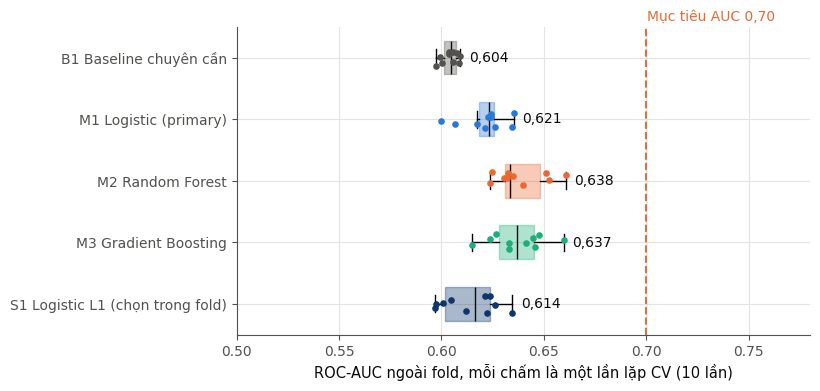

In [28]:
# Hình 1: AUC theo lần lặp
rng_jitter = np.random.default_rng(RANDOM_STATE + 9)   # chỉ dùng để rải điểm trên hình
fig, ax = plt.subplots(figsize=(7.4, 4.0))
keys = ["B1", "M1", "M2", "M3", "S1"]
data = [auc_rep[k].to_numpy() for k in keys]
bp = ax.boxplot(data, vert=False, widths=0.55, patch_artist=True, showfliers=False)
for patch, k in zip(bp["boxes"], keys):
    patch.set_facecolor(MODEL_COLOR[k]); patch.set_alpha(0.35); patch.set_edgecolor(MODEL_COLOR[k])
for med in bp["medians"]:
    med.set_color(INK)
for i, k in enumerate(keys, start=1):
    ax.scatter(auc_rep[k], np.full(N_REPEATS, i) + rng_jitter.uniform(-0.15, 0.15, N_REPEATS), s=14, color=MODEL_COLOR[k], zorder=3)
    ax.text(auc_rep[k].max() + 0.004, i, vi(auc_rep[k].mean(), 3), va="center", fontsize=10, color=INK)
ax.axvline(0.70, color=ORANGE, ls="--", lw=1.4)
ax.text(0.7005, 0.45, "Mục tiêu AUC 0,70", color=ORANGE, fontsize=10, va="bottom")
ax.set_yticks(range(1, 6)); ax.set_yticklabels([MODEL_NAME[k] for k in keys])
ax.invert_yaxis(); ax.set_xlabel("ROC-AUC ngoài fold, mỗi chấm là một lần lặp CV (10 lần)")
ax.set_xlim(0.50, max(0.78, auc_rep.max().max() + 0.04))
save(fig, "f4_01_auc_by_model.png")

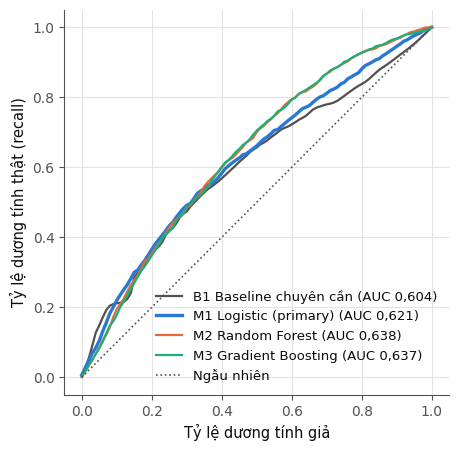

In [29]:
# Hình 2: ROC trung bình
fig, ax = plt.subplots(figsize=(5.6, 5.0))
grid = np.linspace(0, 1, 101)
for k in ("B1", "M1", "M2", "M3"):
    tprs = []
    for r in range(N_REPEATS):
        s_ = S[k][r]
        order = np.argsort(-s_, kind="mergesort")
        ys_ = y[order]; ss_ = s_[order]
        tp = np.cumsum(ys_); fp = np.cumsum(1 - ys_)
        last = np.r_[ss_[1:] != ss_[:-1], True]
        tpr = np.r_[0, tp[last] / npos]; fpr = np.r_[0, fp[last] / (n - npos)]
        tprs.append(np.interp(grid, fpr, tpr))
    tp_m = np.mean(tprs, axis=0)
    ax.plot(grid, tp_m, color=MODEL_COLOR[k], lw=2.4 if k == "M1" else 1.6, label=f"{MODEL_NAME[k]} (AUC {vi(metric_vector(y, S[k])[0], 3)})")
ax.plot([0, 1], [0, 1], color=INK2, ls=":", lw=1.2, label="Ngẫu nhiên")
ax.set_xlabel("Tỷ lệ dương tính giả"); ax.set_ylabel("Tỷ lệ dương tính thật (recall)")
ax.legend(loc="lower right", frameon=False, fontsize=9.5); ax.set_aspect("equal")
save(fig, "f4_02_roc.png")

#### B4.4. Đối chiếu với tiêu chí S1, S2 và quy tắc chọn phương pháp chính

Theo quy tắc đã đăng ký, hồi quy logistic được giữ làm phương pháp chính trừ khi một mô hình cây có AUC cao hơn ít nhất 0,03 **và** cận dưới khoảng tin cậy ghép cặp lớn hơn 0.

In [30]:
# --- 6.4 Tiêu chí thành công đã đăng ký trước
m1 = main_tab.set_index("key").loc["M1"]
d_b1 = [r for r in pair_rows if r["cap"] == "M1 so với B1" and r["metric"] == "AUC"][0]
crit = {
    "S1_AUC_point": bool(m1["AUC"] >= 0.70), "S1_AUC_lower": bool(m1["AUC_lo"] >= 0.70),
    "S1_recall30_point": bool(m1["recall_30"] >= 0.60), "S1_recall30_lower": bool(m1["recall_30_lo"] >= 0.60),
    "S1b_recall15": float(m1["recall_15"]),
    "S2_delta_auc": d_b1["delta"], "S2_met": bool(d_b1["delta"] >= 0.03 and d_b1["lo"] > 0),
}
# quy tắc chọn primary
chg = []
for a in ("M2", "M3"):
    r = [x for x in pair_rows if x["cap"] == f"{a} so với M1" and x["metric"] == "AUC"][0]
    chg.append({"model": a, "delta": r["delta"], "lo": r["lo"], "hi": r["hi"], "switch": bool(r["delta"] >= 0.03 and r["lo"] > 0)})
crit["primary_rule"] = chg

display(pd.Series({k: v for k, v in crit.items() if k != "primary_rule"}, name="Giá trị").to_frame())
display(pd.DataFrame(crit["primary_rule"]).round(3))

,Giá trị
S1_AUC_point,False
S1_AUC_lower,False
S1_recall30_point,False
S1_recall30_lower,False
S1b_recall15,0.261677
S2_delta_auc,0.017081
S2_met,False


,model,delta,lo,hi,switch
0,M2,0.017,-0.016,0.050,False
1,M3,0.016,-0.024,0.058,False


#### B4.5. Hiệu chuẩn xác suất

Độ dốc và hằng số chặn hiệu chuẩn được tính trên mô hình không trọng số M1u (tiêu chí S4) và trên M1 sau khi hiệu chỉnh tỷ lệ nền. Brier score được so với baseline luôn dự đoán tỷ lệ nền. Biểu đồ độ tin cậy nhóm sinh viên theo thập phân vị của xác suất dự đoán.

In [31]:
# --- 6.5 Hiệu chuẩn (mô hình không trọng số và mô hình trọng số hiệu chỉnh theo tỷ lệ nền)
cal_rows = []
for key, P in (("M1u", Pc["M1u"]), ("M1", Pc["M1"])):
    sl, ic, br = [], [], []
    for r in range(N_REPEATS):
        s_, i_ = calib_slope_intercept(y, P[r])
        sl.append(s_); ic.append(i_); br.append(brier_score_loss(y, P[r]))
    cal_rows.append({"model": "M1u Logistic không trọng số" if key == "M1u" else "M1 Logistic trọng số, hiệu chỉnh tỷ lệ nền",
                     "slope": float(np.mean(sl)), "intercept": float(np.mean(ic)), "brier": float(np.mean(br))})
cal_rows.append({"model": "Baseline tỷ lệ nền", "slope": np.nan, "intercept": np.nan, "brier": float(prev * (1 - prev))})
cal = pd.DataFrame(cal_rows)
cal.to_csv(TAB / "t4_calibration.csv", index=False)
crit["S4_slope"] = float(cal.loc[0, "slope"])
crit["S4_met"] = bool(0.8 <= cal.loc[0, "slope"] <= 1.2 and cal.loc[0, "brier"] < prev * (1 - prev))
# bảng độ tin cậy (decile của xác suất trung bình qua các lần lặp)
pm = Pc["M1u"].mean(axis=0)
bins = pd.qcut(pm, 10, duplicates="drop")
rel = pd.DataFrame({"p": pm, "y": y, "bin": bins}).groupby("bin", observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size")).reset_index(drop=True)
rel.to_csv(TAB / "t4_reliability.csv", index=False)
pm1 = Pc["M1"].mean(axis=0)
rel1 = pd.DataFrame({"p": pm1, "y": y, "bin": pd.qcut(pm1, 10, duplicates="drop")}).groupby("bin", observed=True).agg(
    p=("p", "mean"), y=("y", "mean"), n=("y", "size")).reset_index(drop=True)
rel1.to_csv(TAB / "t4_reliability_m1_corrected.csv", index=False)

display(cal.round(4))

,model,slope,intercept,brier
0,M1u Logistic không trọng số,0.6960,-0.4736,0.1350
1,"M1 Logistic trọng số, hiệu chỉnh tỷ lệ nền",0.6678,-0.5169,0.1350
2,Baseline tỷ lệ nền,NaN,NaN,0.1375


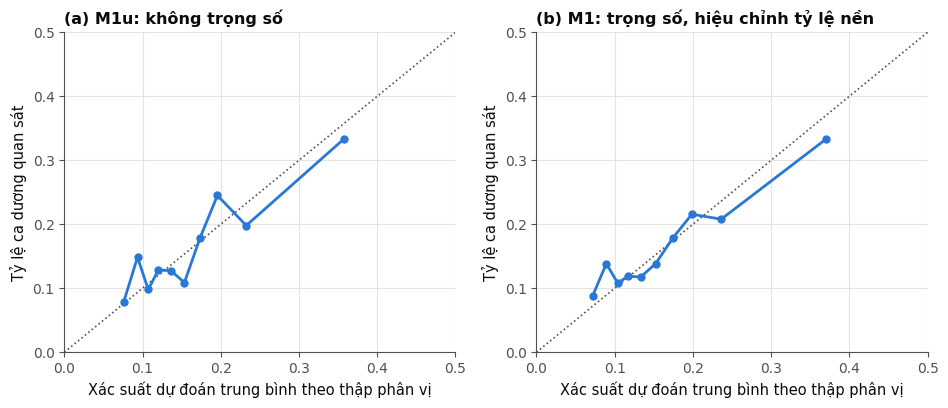

In [32]:
# Hình 4: hiệu chuẩn
fig, axs = plt.subplots(1, 2, figsize=(9.6, 4.2))
for ax, tab, ttl in ((axs[0], rel, "(a) M1u: không trọng số"), (axs[1], rel1, "(b) M1: trọng số, hiệu chỉnh tỷ lệ nền")):
    ax.plot([0, 0.5], [0, 0.5], color=INK2, ls=":", lw=1.2)
    ax.plot(tab["p"], tab["y"], color=BLUE, marker="o", lw=2, ms=5)
    ax.set_xlabel("Xác suất dự đoán trung bình theo thập phân vị"); ax.set_ylabel("Tỷ lệ ca dương quan sát")
    ax.set_title(ttl, loc="left"); mx = max(0.5, float(max(tab["p"].max(), tab["y"].max())) + 0.03)
    ax.set_xlim(0, mx); ax.set_ylim(0, mx)
fig.tight_layout()
save(fig, "f4_04_calibration.png")

### B5. AQ7: đường cong năng lực và điểm vận hành

AQ7 hỏi ở mỗi tỷ lệ gắn cờ, danh sách bắt được bao nhiêu phần trăm sinh viên cần hỗ trợ (recall) và độ chính xác của danh sách (precision) là bao nhiêu; điểm cắt nào đạt recall 60%. Năng lực tư vấn (trần 15% hay 30%) là giả định của stakeholder cần được cố vấn học tập xác nhận.

In [33]:
# --- 6.6 AQ7: đường cong năng lực (recall theo tỷ lệ gắn cờ)
cap_rows = {"rate": list(RATE_GRID)}
capB = {}
for k in ("M1", "B1", "M2", "M3"):
    cap_rows[k] = list(capacity_curve(y, S[k]))
for k in ("M1", "B1"):
    capB[k] = capacity_boot(y, S[k])
    cap_rows[k + "_lo"] = list(np.percentile(capB[k], 2.5, axis=0))
    cap_rows[k + "_hi"] = list(np.percentile(capB[k], 97.5, axis=0))
cap_rows["binormal_auc_M1"] = [binormal_recall(float(m1["AUC"]), q) for q in RATE_GRID]
cap = pd.DataFrame(cap_rows)
cap.to_csv(TAB / "t4_capacity_curve.csv", index=False)
prec_rows = []
for q in RATE_GRID:
    prec_rows.append({"rate": q, "flagged": ceil(q * n),
                      "recall_M1": float(np.mean([recall_at(y, S["M1"][r], q) for r in range(N_REPEATS)])),
                      "precision_M1": float(np.mean([precision_at(y, S["M1"][r], q) for r in range(N_REPEATS)]))})
pd.DataFrame(prec_rows).to_csv(TAB / "t4_operating_points.csv", index=False)
# tỷ lệ gắn cờ tối thiểu để đạt recall 60%
fine = np.round(np.arange(0.05, 0.96, 0.01), 2)
cf = np.array([np.mean([recall_at(y, S["M1"][r], q) for r in range(N_REPEATS)]) for q in fine])
need = float(fine[np.argmax(cf >= 0.60)]) if (cf >= 0.60).any() else float("nan")
R["flag_rate_for_recall60_M1"] = need
cfb = np.array([np.mean([recall_at(y, S["B1"][r], q) for r in range(N_REPEATS)]) for q in fine])
R["flag_rate_for_recall60_B1"] = float(fine[np.argmax(cfb >= 0.60)]) if (cfb >= 0.60).any() else float("nan")

display(pd.DataFrame(prec_rows).round(3))
print("Tỷ lệ gắn cờ tối thiểu để M1 đạt recall 60%:", R["flag_rate_for_recall60_M1"])
print("Tỷ lệ gắn cờ tối thiểu để B1 đạt recall 60%:", R["flag_rate_for_recall60_B1"])

,rate,flagged,recall_M1,precision_M1
0,0.05,51,0.092,0.300
1,0.10,102,0.189,0.310
2,0.15,153,0.262,0.286
3,0.20,203,0.325,0.267
4,0.25,254,0.396,0.261
5,0.30,305,0.457,0.250
6,0.35,356,0.508,0.238
7,0.40,406,0.552,0.227
8,0.45,457,0.604,0.221
9,0.50,508,0.641,0.211


Tỷ lệ gắn cờ tối thiểu để M1 đạt recall 60%: 0.45
Tỷ lệ gắn cờ tối thiểu để B1 đạt recall 60%: 0.47


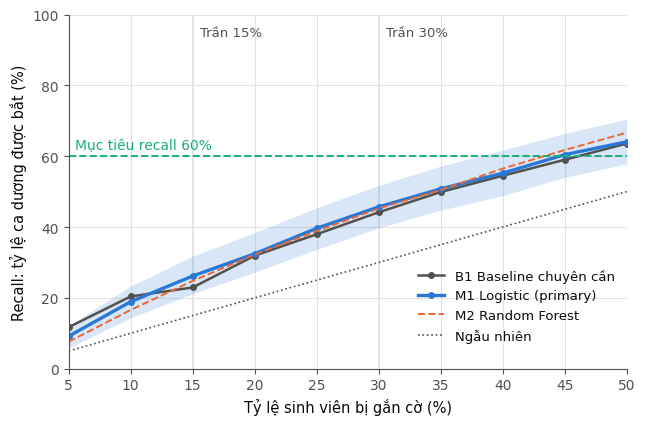

In [34]:
# Hình 3: đường cong năng lực
fig, ax = plt.subplots(figsize=(7.2, 4.6))
x100 = np.array(RATE_GRID) * 100
for k, ls in (("B1", "-"), ("M1", "-")):
    ax.plot(x100, cap[k] * 100, color=MODEL_COLOR[k], lw=2.4 if k == "M1" else 1.8, marker="o", ms=4, label=MODEL_NAME[k])
ax.fill_between(x100, cap["M1_lo"] * 100, cap["M1_hi"] * 100, color=BLUE, alpha=0.18, lw=0)
ax.plot(x100, cap["M2"] * 100, color=ORANGE, lw=1.4, ls="--", label=MODEL_NAME["M2"])
ax.plot(x100, x100, color=INK2, ls=":", lw=1.2, label="Ngẫu nhiên")
ax.axhline(60, color=AQUA, lw=1.4, ls="--"); ax.text(5.5, 62, "Mục tiêu recall 60%", color=AQUA, ha="left", fontsize=10)
for q in FLAG_RATES:
    ax.axvline(q * 100, color=GRID, lw=1.2, zorder=0)
    ax.text(q * 100 + 0.6, 94, f"Trần {int(q * 100)}%", fontsize=9.5, color=INK2)
ax.set_xlabel("Tỷ lệ sinh viên bị gắn cờ (%)"); ax.set_ylabel("Recall: tỷ lệ ca dương được bắt (%)")
ax.set_xlim(5, 50); ax.set_ylim(0, 100); ax.legend(loc="lower right", frameon=False, fontsize=9.5, bbox_to_anchor=(1.0, 0.04))
save(fig, "f4_03_capacity_curve.png")

### B6. AQ5: nhóm tín hiệu và rút gọn bộ tín hiệu

Vì học kỳ và số tín chỉ tương quan rất mạnh, tầm quan trọng của từng biến riêng lẻ không ổn định. Notebook phân tích theo **nhóm tín hiệu** bằng bốn cách bổ trợ nhau:

1. **Hệ số logistic theo fold:** trung bình, độ lệch giữa 50 lần fit và độ ổn định dấu.
2. **Hoán vị theo nhóm** trong fold kiểm tra: AUC giảm bao nhiêu khi xáo trộn một nhóm.
3. **Ablation ghép cặp:** huấn luyện lại khi bỏ hẳn một nhóm, so với mô hình đầy đủ trên cùng mẫu bootstrap. Hai tập rút gọn R3 và R5 được chọn dựa trên EDA của Milestone 3, tức sau khi đã nhìn toàn bộ dữ liệu, nên kết quả của chúng có thể lạc quan và chỉ được coi là phân tích độ nhạy.
4. **Chọn mục khảo sát bằng L1 trong fold:** tần suất mỗi mục được giữ lại và số mục trung bình, là căn cứ chính cho tiêu chí S3 vì không dùng thông tin của phần kiểm tra.

In [35]:
# --- 6.7 AQ5: hệ số, hoán vị theo nhóm, ablation, chọn đặc trưng L1
coef_df = pd.DataFrame([{**r["coef"], "C": r["C"]} for r in info["M1"]])
coef_tab = pd.DataFrame({
    "variable": [c for c in CORE_FEATURES],
    "mean_coef": [coef_df[c].mean() for c in CORE_FEATURES],
    "sd_coef": [coef_df[c].std() for c in CORE_FEATURES],
    "sign_stability": [max((coef_df[c] > 0).mean(), (coef_df[c] < 0).mean()) for c in CORE_FEATURES],
})
coef_tab["or_per_unit"] = np.exp(coef_tab["mean_coef"])
coef_tab.to_csv(TAB / "t4_lr_coefficients.csv", index=False)
R["lr_C_median"] = float(coef_df["C"].median())

perm = pd.DataFrame([r["perm_drop"] for r in perm_info])
perm_tab = pd.DataFrame({"group": perm.columns, "mean_drop": perm.mean().values, "sd_drop": perm.std().values,
                         "share_positive": (perm > 0).mean().values})
perm_tab.to_csv(TAB / "t4_permutation_importance.csv", index=False)

abl_S = {}
for g, gc in GROUPS.items():
    cols = [c for c in CORE_FEATURES if c not in gc]
    abl_S[g], _, _ = run_cv("M1", X, y, splits, cols=cols)
# tập rút gọn lấy từ EDA Milestone 3 (có thể lạc quan do chọn trên toàn bộ dữ liệu)
red_sets = {"R3 (chuyên cần, tiếng Anh, học kỳ)": ["attendance_pct", "english_basic", "english_advance", "semester_capped"],
            "R5 (R3 cộng giờ mạng xã hội, giờ học)": ["attendance_pct", "english_basic", "english_advance", "semester_capped", "social_hours", "study_hours"]}
red_S = {}
for nm, cols in red_sets.items():
    red_S[nm], _, _ = run_cv("M1", X, y, splits, cols=cols)
S_abl_all = {"Đầy đủ": S["M1"], **{f"Bỏ nhóm: {g}": v for g, v in abl_S.items()}, **red_S}
Babl = bootstrap_all(y, S_abl_all, n_boot=1000, seed=RANDOM_STATE + 2)
abl_rows = []
for k, v in S_abl_all.items():
    d = Babl[k][:, 0] - Babl["Đầy đủ"][:, 0]
    lo, hi = ci(d)
    cols_used = CORE_FEATURES if k == "Đầy đủ" else None
    abl_rows.append({"setting": k, "auc": float(metric_vector(y, v)[0]), "recall_30": float(metric_vector(y, v)[2]),
                     "delta_auc": float(metric_vector(y, v)[0] - metric_vector(y, S["M1"])[0]), "lo": lo, "hi": hi})
pd.DataFrame(abl_rows).to_csv(TAB / "t4_ablation.csv", index=False)
items_in = {"R3 (chuyên cần, tiếng Anh, học kỳ)": 3, "R5 (R3 cộng giờ mạng xã hội, giờ học)": 5}

l1_items = [set(r["selected_items"]) for r in info["S1"]]
sel_freq = pd.DataFrame({"item": sorted(set(ITEM_OF.values())),
                         "freq": [float(np.mean([i in s for s in l1_items])) for i in sorted(set(ITEM_OF.values()))]})
sel_freq.to_csv(TAB / "t4_l1_selection_frequency.csv", index=False)
R["l1_items_mean"] = float(np.mean([len(s) for s in l1_items]))
R["l1_items_sd"] = float(np.std([len(s) for s in l1_items]))
R["l1_items_max"] = int(np.max([len(s) for s in l1_items]))
R["l1_share_le8"] = float(np.mean([len(s) <= 8 for s in l1_items]))
s1_pt = main_tab.set_index("key").loc["S1"]
R["S3"] = {"auc_S1": float(s1_pt["AUC"]), "auc_M1": float(m1["AUC"]), "delta": float(s1_pt["AUC"] - m1["AUC"]),
           "items_mean": R["l1_items_mean"], "met": bool(R["l1_items_mean"] <= 8 and (m1["AUC"] - s1_pt["AUC"]) <= 0.02)}

display(Markdown("**Hệ số logistic của M1 qua các fold**"))
display(coef_tab.round(3))
display(Markdown("**Hoán vị theo nhóm**"))
display(perm_tab.round(3))
display(Markdown("**Ablation và tập rút gọn**"))
display(pd.DataFrame(abl_rows).round(3))
display(Markdown("**Tần suất chọn mục bởi L1 trong fold**"))
display(sel_freq.round(2))
print("Tiêu chí S3:", R["S3"])

**Hệ số logistic của M1 qua các fold**

,variable,mean_coef,sd_coef,sign_stability,or_per_unit
0,study_hours,-0.098,0.064,0.94,0.906
1,study_sessions,0.064,0.070,0.80,1.066
2,attendance_pct,-0.474,0.072,1.00,0.622
3,social_hours,0.032,0.043,0.78,1.032
4,skill_hours,0.000,0.073,0.52,1.000
5,learning_mode_online,0.156,0.099,0.94,1.168
6,has_pc,-0.226,0.160,0.90,0.798
7,uses_transport,-0.255,0.089,1.00,0.775
8,english_basic,0.791,0.185,1.00,2.206
9,english_advance,0.484,0.163,1.00,1.623


**Hoán vị theo nhóm**

,group,mean_drop,sd_drop,share_positive
0,Thói quen học tập,0.063,0.032,0.98
1,Trình độ tiếng Anh,0.052,0.029,0.96
2,Tiến độ học vụ,0.006,0.014,0.70
3,Bối cảnh học tập,0.006,0.014,0.66


**Ablation và tập rút gọn**

,setting,auc,recall_30,delta_auc,lo,hi
0,Đầy đủ,0.621,0.457,0.000,0.000,0.000
1,Bỏ nhóm: Thói quen học tập,0.589,0.393,-0.032,-0.067,0.003
2,Bỏ nhóm: Trình độ tiếng Anh,0.581,0.412,-0.040,-0.072,-0.008
3,Bỏ nhóm: Tiến độ học vụ,0.616,0.442,-0.005,-0.019,0.009
4,Bỏ nhóm: Bối cảnh học tập,0.626,0.457,0.005,-0.013,0.021
5,"R3 (chuyên cần, tiếng Anh, học kỳ)",0.638,0.454,0.016,-0.005,0.038
6,"R5 (R3 cộng giờ mạng xã hội, giờ học)",0.631,0.449,0.010,-0.011,0.028


**Tần suất chọn mục bởi L1 trong fold**

,item,freq
0,attendance_pct,1.00
1,cocurricular,0.76
2,credits_completed,0.58
3,english,0.84
4,has_pc,0.62
5,learning_mode_online,0.66
6,semester_capped,0.70
7,skill_hours,0.62
8,social_hours,0.72
9,study_hours,0.66


Tiêu chí S3: {'auc_S1': 0.6140104225511243, 'auc_M1': 0.6211942859563891, 'delta': -0.00718386340526489, 'items_mean': 8.58, 'met': False}


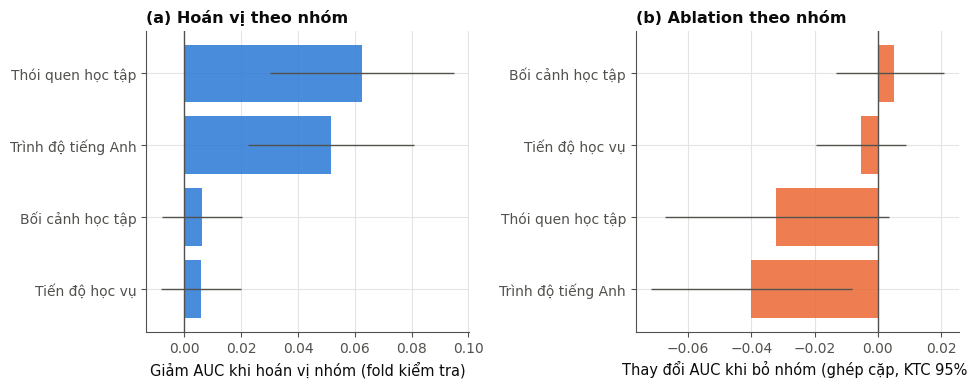

In [36]:
# Hình 5: nhóm tín hiệu (hoán vị và ablation)
fig, axs = plt.subplots(1, 2, figsize=(9.8, 4.0))
pt = perm_tab.sort_values("mean_drop")
axs[0].barh(pt["group"], pt["mean_drop"], xerr=pt["sd_drop"], color=BLUE, alpha=0.85, error_kw={"ecolor": INK2, "lw": 1})
axs[0].axvline(0, color=INK2, lw=1)
axs[0].set_xlabel("Giảm AUC khi hoán vị nhóm (fold kiểm tra)"); axs[0].set_title("(a) Hoán vị theo nhóm", loc="left")
ab = pd.DataFrame(abl_rows)
ab = ab[ab["setting"].str.startswith("Bỏ nhóm")].sort_values("delta_auc")
axs[1].barh([s.replace("Bỏ nhóm: ", "") for s in ab["setting"]], ab["delta_auc"], color=ORANGE, alpha=0.85)
axs[1].errorbar(ab["delta_auc"], range(len(ab)), xerr=[ab["delta_auc"] - ab["lo"], ab["hi"] - ab["delta_auc"]], fmt="none", ecolor=INK2, lw=1)
axs[1].axvline(0, color=INK2, lw=1); axs[1].set_xlabel("Thay đổi AUC khi bỏ nhóm (ghép cặp, KTC 95%)")
axs[1].set_title("(b) Ablation theo nhóm", loc="left")
fig.tight_layout()
save(fig, "f4_05_group_importance.png")

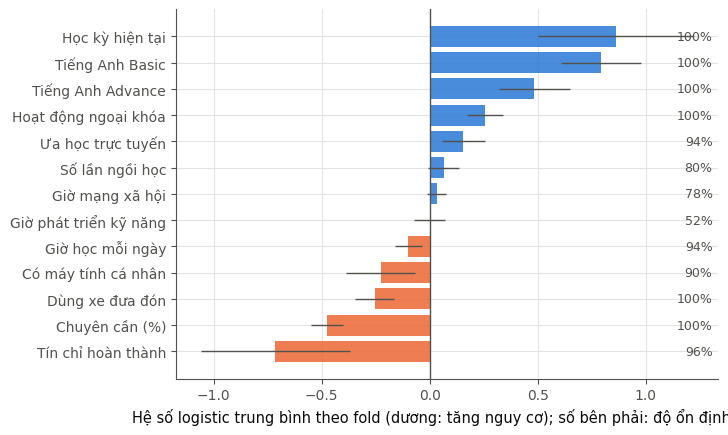

In [37]:
# Hình 6: hệ số logistic theo fold
fig, ax = plt.subplots(figsize=(7.0, 4.8))
ct = coef_tab.sort_values("mean_coef")
colors = [BLUE if v > 0 else ORANGE for v in ct["mean_coef"]]
ax.barh([LABEL[v] for v in ct["variable"]], ct["mean_coef"], xerr=ct["sd_coef"], color=colors, alpha=0.85, error_kw={"ecolor": INK2, "lw": 1})
for i, (v, s_) in enumerate(zip(ct["mean_coef"], ct["sign_stability"])):
    ax.text(ax.get_xlim()[1] * 0.98, i, f"{int(round(s_ * 100))}%", va="center", ha="right", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlabel("Hệ số logistic trung bình theo fold (dương: tăng nguy cơ); số bên phải: độ ổn định dấu")
save(fig, "f4_06_lr_coefficients.png")

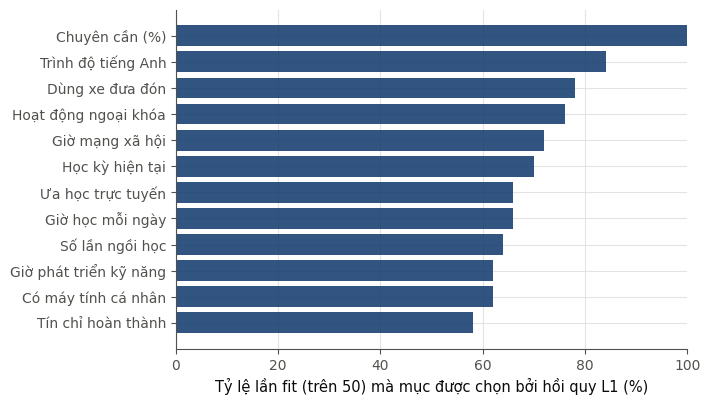

In [38]:
# Hình 9: tần suất chọn mục bởi L1
fig, ax = plt.subplots(figsize=(6.6, 4.4))
sf = sel_freq.sort_values("freq")
ax.barh([LABEL[i] for i in sf["item"]], sf["freq"] * 100, color=BLUE_DARK, alpha=0.85)
ax.set_xlabel("Tỷ lệ lần fit (trên 50) mà mục được chọn bởi hồi quy L1 (%)"); ax.set_xlim(0, 100)
save(fig, "f4_09_l1_selection.png")

### B7. AQ6: kiểm định công bằng theo phân nhóm

Điểm sàng lọc của M1 (trung bình qua các lần lặp, vẫn là điểm ngoài fold) được cắt tại **một ngưỡng chung** cho mọi sinh viên ở tỷ lệ gắn cờ 15% và 30%. Với từng nhóm giới tính và nơi ở, notebook tính tỷ lệ nền, tỷ lệ gắn cờ, recall và precision kèm khoảng tin cậy Wilson. Chênh lệch recall giữa hai nhóm (tinh thần equality of opportunity) có khoảng tin cậy bootstrap; theo tiêu chí S5, nếu khoảng tin cậy rộng hơn 20 điểm phần trăm thì kết luận là chưa kết luận được. Giới tính và nơi ở chỉ được dùng để kiểm tra, không là đặc trưng của mô hình.

In [39]:
# --- 6.8 AQ6: công bằng tại ngưỡng chung
ms = {k: S[k].mean(axis=0) for k in S}           # điểm trung bình các lần lặp (vẫn là điểm ngoài fold)
rng = np.random.default_rng(RANDOM_STATE + 3)
fair_rows, gap_rows = [], []
fair_cols = {"gender": "Giới tính", "living_with": "Nơi ở"}
for rate in FLAG_RATES:
    k_n = ceil(rate * n)
    thr = np.sort(ms["M1"])[::-1][k_n - 1]
    flag = ms["M1"] >= thr
    for col, nm in fair_cols.items():
        levels = sorted(df[col].dropna().unique())
        stats_g = {}
        for lv in levels:
            m = (df[col] == lv).to_numpy()
            tp = int((flag & m & (y == 1)).sum()); pos = int((m & (y == 1)).sum()); fl = int((flag & m).sum()); nn = int(m.sum())
            rlo, rhi = wilson(tp, pos); plo, phi = wilson(tp, fl) if fl else (np.nan, np.nan)
            stats_g[lv] = (tp, pos, fl, nn)
            fair_rows.append({"rate": rate, "attribute": nm, "group": lv, "n": nn, "positives": pos, "base_rate": pos / nn,
                              "flag_rate": fl / nn, "recall": tp / pos, "recall_lo": rlo, "recall_hi": rhi,
                              "precision": tp / fl if fl else np.nan, "precision_lo": plo, "precision_hi": phi,
                              "auc": auc_rank(y[m], ms["M1"][m])})
        a, b = levels[0], levels[1]
        gap = stats_g[a][0] / stats_g[a][1] - stats_g[b][0] / stats_g[b][1]
        bs = []
        ma, mb = (df[col] == a).to_numpy(), (df[col] == b).to_numpy()
        for _ in range(N_BOOT):
            idx = rng.integers(0, n, n)
            ys, ss, aa, bb = y[idx], ms["M1"][idx], ma[idx], mb[idx]
            tt = np.sort(ss)[::-1][k_n - 1]
            fg = ss >= tt
            ra = (fg & aa & (ys == 1)).sum() / max((aa & (ys == 1)).sum(), 1)
            rb = (fg & bb & (ys == 1)).sum() / max((bb & (ys == 1)).sum(), 1)
            bs.append(ra - rb)
        lo, hi = ci(np.array(bs))
        gap_rows.append({"rate": rate, "attribute": nm, "group_a": a, "group_b": b, "gap_recall": float(gap), "lo": lo, "hi": hi,
                         "ci_width": hi - lo, "within_10": bool(abs(gap) <= 0.10), "conclusive": bool((hi - lo) <= 0.20)})
pd.DataFrame(fair_rows).to_csv(TAB / "t4_fairness_groups.csv", index=False)
gaps = pd.DataFrame(gap_rows)
gaps.to_csv(TAB / "t4_fairness_gaps.csv", index=False)
crit["S5"] = gap_rows

display(Markdown("**Chỉ số theo nhóm**"))
display(pd.DataFrame(fair_rows).round(3))
display(Markdown("**Chênh lệch recall giữa các nhóm**"))
display(gaps.round(3))

**Chỉ số theo nhóm**

,rate,attribute,group,n,positives,base_rate,flag_rate,recall,recall_lo,recall_hi,precision,precision_lo,precision_hi,auc
0,0.15,Giới tính,Female,453,71,0.157,0.159,0.310,0.214,0.425,0.306,0.211,0.420,0.636
1,0.15,Giới tính,Male,562,96,0.171,0.144,0.240,0.165,0.334,0.284,0.197,0.390,0.616
2,0.15,Nơi ở,Bachelor,475,96,0.202,0.147,0.250,0.174,0.345,0.343,0.242,0.460,0.603
3,0.15,Nơi ở,Family,540,71,0.131,0.154,0.296,0.202,0.410,0.253,0.172,0.356,0.650
4,0.30,Giới tính,Female,453,71,0.157,0.285,0.451,0.340,0.566,0.248,0.182,0.329,0.636
5,0.30,Giới tính,Male,562,96,0.171,0.313,0.469,0.372,0.568,0.256,0.197,0.325,0.616
6,0.30,Nơi ở,Bachelor,475,96,0.202,0.333,0.479,0.382,0.578,0.291,0.226,0.366,0.603
7,0.30,Nơi ở,Family,540,71,0.131,0.272,0.437,0.327,0.552,0.211,0.153,0.284,0.650


**Chênh lệch recall giữa các nhóm**

,rate,attribute,group_a,group_b,gap_recall,lo,hi,ci_width,within_10,conclusive
0,0.15,Giới tính,Female,Male,0.070,-0.099,0.185,0.284,True,False
1,0.15,Nơi ở,Bachelor,Family,-0.046,-0.175,0.103,0.278,True,False
2,0.30,Giới tính,Female,Male,-0.018,-0.173,0.138,0.311,True,False
3,0.30,Nơi ở,Bachelor,Family,0.043,-0.100,0.211,0.311,True,False


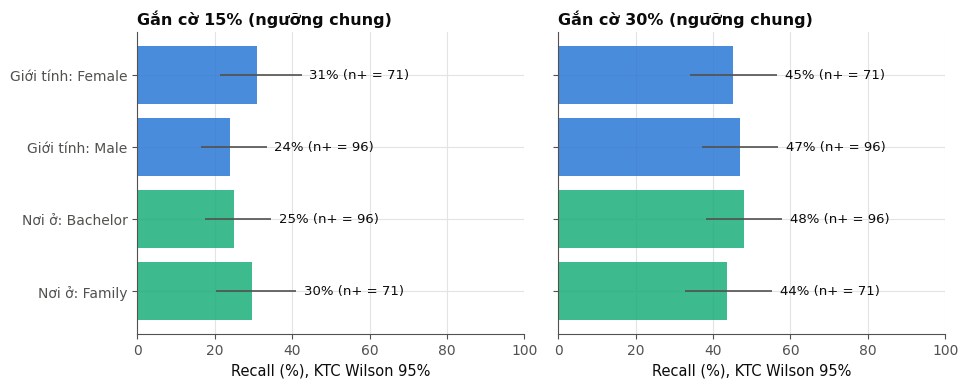

In [40]:
# Hình 7: công bằng
fg = pd.DataFrame(fair_rows)
fig, axs = plt.subplots(1, 2, figsize=(9.8, 4.0), sharey=True)
for ax, rate in zip(axs, FLAG_RATES):
    sub = fg[fg["rate"] == rate].reset_index(drop=True)
    labels = [f"{a}: {g}" for a, g in zip(sub["attribute"], sub["group"])]
    cols_ = [BLUE if a == "Giới tính" else AQUA for a in sub["attribute"]]
    ax.barh(labels, sub["recall"] * 100, color=cols_, alpha=0.85)
    ax.errorbar(sub["recall"] * 100, range(len(sub)), xerr=[(sub["recall"] - sub["recall_lo"]) * 100, (sub["recall_hi"] - sub["recall"]) * 100],
                fmt="none", ecolor=INK2, lw=1.2)
    for i, (r_, nn) in enumerate(zip(sub["recall"], sub["positives"])):
        ax.text(sub["recall_hi"].iloc[i] * 100 + 2, i, f"{r_ * 100:.0f}% (n+ = {nn})", va="center", fontsize=9.5, color=INK)
    ax.set_xlim(0, 100); ax.set_title(f"Gắn cờ {int(rate * 100)}% (ngưỡng chung)", loc="left"); ax.set_xlabel("Recall (%), KTC Wilson 95%")
axs[0].invert_yaxis()
fig.tight_layout()
save(fig, "f4_07_fairness.png")

### B8. AQ2 và AQ3: mô hình hiệu chỉnh

Với từng đặc trưng, notebook ước lượng OR không hiệu chỉnh (mô hình một biến) và OR hiệu chỉnh trong ba mô hình: A gồm thói quen học tập và học kỳ, B gồm các biến bối cảnh của AQ3, C gồm toàn bộ đặc trưng trừ số tín chỉ (bỏ để tránh cộng tuyến với học kỳ). Giá trị p của mô hình C được hiệu chỉnh Holm. Kết quả chỉ diễn giải ở mức **liên hệ**: dữ liệu không có can thiệp nên không cho phép kết luận rằng thay đổi một thói quen sẽ thay đổi kết quả học tập.

In [41]:
# --- 6.9 AQ2 và AQ3: mô hình hiệu chỉnh và liên hệ không hiệu chỉnh
uni = pd.concat([logit_wald(X, y, [c]).assign(model="unadjusted") for c in CORE_FEATURES], ignore_index=True)
A_cols = GROUPS["Thói quen học tập"] + ["semester_capped"]
B_cols = ["learning_mode_online", "has_pc", "uses_transport", "english_basic", "english_advance", "semester_capped", "cocurricular"]
C_cols = [c for c in CORE_FEATURES if c != "credits_completed"]
adj = pd.concat([logit_wald(X, y, A_cols).assign(model="A: AQ2 + học kỳ"), logit_wald(X, y, B_cols).assign(model="B: AQ3"),
                 logit_wald(X, y, C_cols).assign(model="C: đầy đủ, không có tín chỉ")], ignore_index=True)
adj.loc[adj.model == "C: đầy đủ, không có tín chỉ", "p_holm"] = holm(adj.loc[adj.model == "C: đầy đủ, không có tín chỉ", "p"].tolist())
pd.concat([uni, adj], ignore_index=True).to_csv(TAB / "t4_adjusted_models.csv", index=False)

display(adj[adj.model.str.startswith("C")].round(4))

,variable,or,lo,hi,p,model,p_holm
13,study_hours,0.9409,0.7767,1.1399,0.5339,"C: đầy đủ, không có tín chỉ",1.0000
14,study_sessions,1.0147,0.8407,1.2246,0.8795,"C: đầy đủ, không có tín chỉ",1.0000
15,attendance_pct,0.7053,0.6087,0.8172,0.0000,"C: đầy đủ, không có tín chỉ",0.0000
16,social_hours,1.0331,0.8749,1.2198,0.7011,"C: đầy đủ, không có tín chỉ",1.0000
17,skill_hours,0.9715,0.8102,1.1648,0.7547,"C: đầy đủ, không có tín chỉ",1.0000
18,learning_mode_online,1.1744,0.8066,1.7100,0.4016,"C: đầy đủ, không có tín chỉ",1.0000
19,has_pc,0.7454,0.4168,1.3329,0.3217,"C: đầy đủ, không có tín chỉ",1.0000
20,uses_transport,0.8057,0.5632,1.1527,0.2371,"C: đầy đủ, không có tín chỉ",1.0000
21,english_basic,2.2998,1.5227,3.4736,0.0001,"C: đầy đủ, không có tín chỉ",0.0008
22,english_advance,1.5347,0.9829,2.3963,0.0596,"C: đầy đủ, không có tín chỉ",0.5956


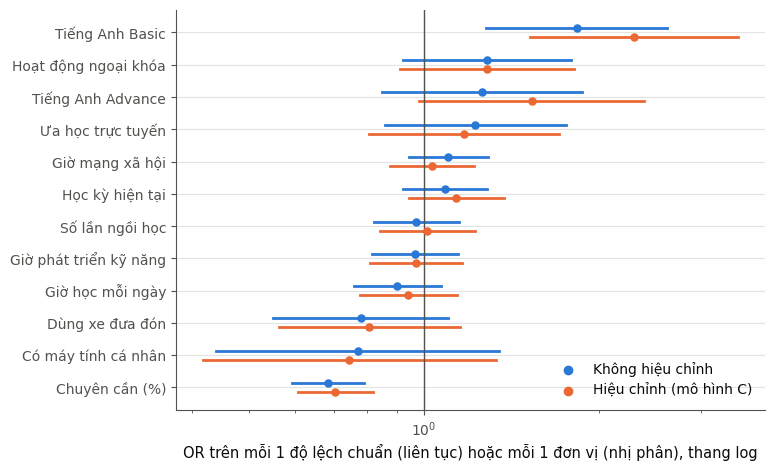

In [42]:
# Hình 8: OR không hiệu chỉnh và hiệu chỉnh
fig, ax = plt.subplots(figsize=(7.6, 5.2))
cc = adj[adj.model.str.startswith("C")].set_index("variable")
un = uni.set_index("variable")
order = [c for c in un.sort_values("or").index if c in cc.index]
for i, c in enumerate(order):
    ax.plot([un.loc[c, "lo"], un.loc[c, "hi"]], [i + 0.14, i + 0.14], color=BLUE, lw=2)
    ax.scatter(un.loc[c, "or"], i + 0.14, color=BLUE, s=26, zorder=3)
    ax.plot([cc.loc[c, "lo"], cc.loc[c, "hi"]], [i - 0.14, i - 0.14], color=ORANGE, lw=2)
    ax.scatter(cc.loc[c, "or"], i - 0.14, color=ORANGE, s=26, zorder=3)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log"); ax.set_yticks(range(len(order))); ax.set_yticklabels([LABEL[c] for c in order])
ax.set_xlabel("OR trên mỗi 1 độ lệch chuẩn (liên tục) hoặc mỗi 1 đơn vị (nhị phân), thang log")
ax.scatter([], [], color=BLUE, label="Không hiệu chỉnh"); ax.scatter([], [], color=ORANGE, label="Hiệu chỉnh (mô hình C)")
ax.legend(loc="lower right", frameon=False)
save(fig, "f4_08_adjusted_or.png")

### B9. Phân tích độ nhạy và lưu điểm ngoài fold

Phân tích độ nhạy lặp lại B1 và M1 với hai ngưỡng nhãn khác (2,50 và 3,00) và trên mẫu độ nhạy B (giữ 140 dòng thuộc cặp lặp), để kiểm tra kết luận có phụ thuộc vào ngưỡng hoặc vào quyết định loại cặp lặp ở Milestone 3 hay không. Sau đó, điểm ngoài fold của các mô hình, cờ gắn tại 15% và 30% và thứ hạng ưu tiên được lưu thành `oof_predictions_m4.csv`, làm nguồn dữ liệu cho dashboard ở Milestone 5.

In [43]:
# --- 6.10 Độ nhạy: nhãn 2,50 và 3,00; mẫu B
sens_rows = []
for tgt in ("y_lt_2_50", "y_lt_2_75", "y_lt_3_00"):
    dft = pd.read_csv(data_path)
    yt = dft[tgt].to_numpy().astype(int)
    sp = split_list(dft[CORE_FEATURES], yt)
    for key, cols in (("B1", ["attendance_pct"]), ("M1", None)):
        Ss, _, _ = run_cv(key, dft[CORE_FEATURES], yt, sp, cols=cols)
        mv = metric_vector(yt, Ss)
        sens_rows.append({"sample": "Mẫu chính", "target": tgt, "model": key, "positives": int(yt.sum()), "AUC": float(mv[0]),
                          "recall_15": float(mv[1]), "recall_30": float(mv[2])})
master = pd.read_csv(ROOT / "data" / "processed" / "m3_analytic_master.csv")
mb = master[master["in_sensitivity_B"] == 1].reset_index(drop=True)
yb = mb[PRIMARY_TARGET].to_numpy().astype(int)
spb = split_list(mb[CORE_FEATURES], yb)
for key, cols in (("B1", ["attendance_pct"]), ("M1", None)):
    Ss, _, _ = run_cv(key, mb[CORE_FEATURES], yb, spb, cols=cols)
    mv = metric_vector(yb, Ss)
    sens_rows.append({"sample": "Mẫu độ nhạy B", "target": PRIMARY_TARGET, "model": key, "positives": int(yb.sum()), "AUC": float(mv[0]),
                      "recall_15": float(mv[1]), "recall_30": float(mv[2])})
pd.DataFrame(sens_rows).to_csv(TAB / "t4_sensitivity.csv", index=False)

display(pd.DataFrame(sens_rows).round(3))

,sample,target,model,positives,AUC,recall_15,recall_30
0,Mẫu chính,y_lt_2_50,B1,52,0.540,0.150,0.326
1,Mẫu chính,y_lt_2_50,M1,52,0.686,0.358,0.602
2,Mẫu chính,y_lt_2_75,B1,167,0.604,0.229,0.442
3,Mẫu chính,y_lt_2_75,M1,167,0.621,0.262,0.457
4,Mẫu chính,y_lt_3_00,B1,311,0.637,0.234,0.459
5,Mẫu chính,y_lt_3_00,M1,311,0.650,0.258,0.461
6,Mẫu độ nhạy B,y_lt_2_75,B1,167,0.604,0.256,0.451
7,Mẫu độ nhạy B,y_lt_2_75,M1,167,0.621,0.274,0.463


In [44]:
# --- 6.11 Lưu điểm ngoài fold (phục vụ Milestone 5 và dashboard)
oof = pd.DataFrame({"rid": df["rid"], "y_lt_2_75": y, "score_M1": ms["M1"], "score_B1": ms["B1"], "score_M2": ms["M2"], "score_M3": ms["M3"],
                    "prob_M1_corrected": Pc["M1"].mean(axis=0), "gender": df["gender"], "living_with": df["living_with"]})
for rate in FLAG_RATES:
    thr = np.sort(ms["M1"])[::-1][ceil(rate * n) - 1]
    oof[f"flag_{int(rate * 100)}"] = (ms["M1"] >= thr).astype(int)
oof["risk_rank"] = oof["score_M1"].rank(ascending=False, method="first").astype(int)
oof.to_csv(OUT / "oof_predictions_m4.csv", index=False)

display(oof.head())

,rid,y_lt_2_75,score_M1,score_B1,score_M2,score_M3,prob_M1_corrected,gender,living_with,flag_15,flag_30,risk_rank
0,8,0,0.509527,0.488391,0.440175,0.435254,0.170612,Female,Bachelor,0,0,373
1,12,0,0.552604,0.496035,0.527193,0.559720,0.196375,Male,Bachelor,0,1,258
2,16,0,0.529662,0.492264,0.439682,0.373526,0.182507,Male,Family,0,0,313
3,19,0,0.639163,0.511689,0.422922,0.221056,0.260409,Male,Family,1,1,110
4,21,0,0.392322,0.491800,0.292648,0.295018,0.113291,Female,Bachelor,0,0,682


### B10. Tổng hợp kết quả và nhật ký thực nghiệm

Ô dưới đây lưu `results_m4.json` (mọi con số được dùng ở Mục 7 của báo cáo) và `experiment_log_m4.json` (phiên bản thư viện, hạt giống, mã băm dữ liệu, kế hoạch và từng bảng đầu ra, thời gian chạy).

In [45]:
R["criteria"] = crit
R["main_ranking"] = main_tab[["key", "AUC", "AUC_lo", "AUC_hi", "recall_30", "recall_30_lo", "recall_30_hi", "recall_15", "pr_auc"]].to_dict(orient="records")
R["items_reduced"] = items_in
with open(OUT / "results_m4.json", "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
log["thoi_gian_chay_giay"] = round(time.time() - t0, 1)
log["ket_thuc_utc"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
log["sha256_dau_ra"] = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(TAB.glob("*.csv"))}
with open(OUT / "experiment_log_m4.json", "w", encoding="utf-8") as f:
    json.dump(log, f, ensure_ascii=False, indent=2)
print("Hoàn tất thực nghiệm Level 2:", len(list(FIG.glob("*.png"))), "hình,", len(list(TAB.glob("*.csv"))), "bảng, thời gian", log["thoi_gian_chay_giay"], "giây")

Hoàn tất thực nghiệm Level 2: 9 hình, 17 bảng, thời gian 500.6 giây


#### B10.1. Bảng chấm tiêu chí thành công

Bảng chấm đọc trực tiếp từ kết quả vừa tính, đối chiếu với các tiêu chí đã đăng ký trước ở Mục 2.2.

In [46]:
c = R["criteria"]
m1_row = main_tab.set_index("key").loc["M1"]
s5_ok = all(g["within_10"] for g in c["S5"])
s5_conclusive = all(g["conclusive"] for g in c["S5"])
score = pd.DataFrame([
    ("S1", "AUC ≥ 0,70 và recall ≥ 60% tại 30%",
     f"AUC {m1_row['AUC']:.3f}; recall {m1_row['recall_30']:.1%}",
     "Đạt" if c["S1_AUC_point"] and c["S1_recall30_point"] else "Không đạt"),
    ("S1b", "Báo cáo recall tại 15% (tham chiếu 60%)", f"recall {c['S1b_recall15']:.1%}",
     "Đạt" if c["S1b_recall15"] >= 0.60 else "Không đạt"),
    ("S2", "ΔAUC so với B1 ≥ 0,03 và cận dưới KTC > 0", f"ΔAUC {c['S2_delta_auc']:.3f}",
     "Đạt" if c["S2_met"] else "Không đạt"),
    ("S3", "≤ 8 mục và AUC giảm ≤ 0,02",
     f"{R['S3']['items_mean']:.2f} mục; AUC giảm {abs(R['S3']['delta']):.3f}", "Đạt" if R["S3"]["met"] else "Không đạt"),
    ("S4", "Độ dốc hiệu chuẩn trong [0,8; 1,2] và Brier thấp hơn tỷ lệ nền", f"độ dốc {c['S4_slope']:.2f}",
     "Đạt" if c["S4_met"] else "Không đạt"),
    ("S5", "Chênh lệch recall ≤ 10 điểm, KTC không rộng quá 20 điểm",
     f"điểm ước lượng {'≤' if s5_ok else '>'} 10 điểm; KTC rộng nhất {max(g['ci_width'] for g in c['S5']):.0%}",
     "Đạt" if s5_ok and s5_conclusive else ("Chưa kết luận được" if s5_ok else "Không đạt")),
    ("Quy tắc chọn", "Mô hình cây vượt ≥ 0,03 và cận dưới > 0",
     "; ".join(f"{r['model']} {r['delta']:+.3f} [{r['lo']:.3f}; {r['hi']:.3f}]" for r in c["primary_rule"]),
     "Đổi phương pháp chính" if any(r["switch"] for r in c["primary_rule"]) else "Giữ hồi quy logistic"),
], columns=["Mã", "Tiêu chí đăng ký trước", "Kết quả quan sát", "Kết luận"])
score["Kết quả quan sát"] = score["Kết quả quan sát"].str.replace(".", ",", regex=False)   # dấu thập phân kiểu Việt Nam
display(score)

,Mã,Tiêu chí đăng ký trước,Kết quả quan sát,Kết luận
0,S1,"AUC ≥ 0,70 và recall ≥ 60% tại 30%","AUC 0,621; recall 45,7%",Không đạt
1,S1b,Báo cáo recall tại 15% (tham chiếu 60%),"recall 26,2%",Không đạt
2,S2,"ΔAUC so với B1 ≥ 0,03 và cận dưới KTC > 0","ΔAUC 0,017",Không đạt
3,S3,"≤ 8 mục và AUC giảm ≤ 0,02","8,58 mục; AUC giảm 0,007",Không đạt
4,S4,"Độ dốc hiệu chuẩn trong [0,8; 1,2] và Brier thấp hơn tỷ lệ nền","độ dốc 0,70",Không đạt
5,S5,"Chênh lệch recall ≤ 10 điểm, KTC không rộng quá 20 điểm",điểm ước lượng ≤ 10 điểm; KTC rộng nhất 31%,Chưa kết luận được
6,Quy tắc chọn,"Mô hình cây vượt ≥ 0,03 và cận dưới > 0","M2 +0,017 [-0,016; 0,050]; M3 +0,016 [-0,024; 0,058]",Giữ hồi quy logistic


#### B10.2. Đối chiếu với kết quả trong báo cáo

Ô cuối so sánh mã băm từng bảng đầu ra với gói dữ liệu đã nộp kèm báo cáo, và so sánh các chỉ số chính với giá trị trong báo cáo (sai lệch cho phép 0,005). Tệp điểm ngoài fold không được so từng byte vì Random Forest cộng xác suất của các cây song song, nên chữ số thập phân thứ 16 có thể khác giữa hai lần chạy mà không ảnh hưởng đến bất kỳ bảng hay chỉ số nào. Kết quả trong báo cáo được tạo với scikit-learn 1.9.1; nếu Colab dùng phiên bản khác, một số bảng có thể không trùng từng byte do khác biệt số học rất nhỏ giữa các phiên bản, trong khi các chỉ số chính vẫn nằm trong sai lệch cho phép và kết luận không đổi.

In [47]:
EXPECTED_SHA256 = {
    "reports/milestone4/tables/t4_ablation.csv": "2822af3485059f5fa9566d93acf5a5c2d05f39fa8b072259c1b0cc36996c0cf6",
    "reports/milestone4/tables/t4_adjusted_models.csv": "a8aeca59b054d75e0a37b5c51aaffece8a575e7a89d7555aa64f4fbead0d0e3b",
    "reports/milestone4/tables/t4_auc_by_repeat.csv": "b2a13d59a4eeec5d678b67500f7dd16811340cbfa90b26378c1b3e5a114947a2",
    "reports/milestone4/tables/t4_b0_reference.csv": "05bf9a086dcd4b0554c86298ff638f63c6eb9717eb88336759981bf537c8c417",
    "reports/milestone4/tables/t4_calibration.csv": "b0e01da01e4871f377798e0e7d9352e1e89d507712b25cc2bd80a2dc90e60625",
    "reports/milestone4/tables/t4_capacity_curve.csv": "3e76ed294956ded04e7188abcadc3b76bc2950b428ba7bde03eb29e36e4bb362",
    "reports/milestone4/tables/t4_fairness_gaps.csv": "8ffe968c41f5163d202ec3caafc9af7fa7e1dbccd6b033876609668af138eb93",
    "reports/milestone4/tables/t4_fairness_groups.csv": "3a0cdebc97506265cafebff76035bb50d9d9b7d3fd33b4b96c99ffad8bf54246",
    "reports/milestone4/tables/t4_l1_selection_frequency.csv": "cf1a6c9816ce6a4a540303e655b9398c05713a98c23d7348dae3af9361512359",
    "reports/milestone4/tables/t4_lr_coefficients.csv": "be1c32eede48d8ae8d7b1589e45af92ca524f45df5415b61b6a92187e081ee47",
    "reports/milestone4/tables/t4_main_results.csv": "7add753f2744863dc4f4f05dbc2cfad4015362a12f757b622302c28d56b54210",
    "reports/milestone4/tables/t4_operating_points.csv": "a4d0f78beae0b224cca7cec1e776b46cd00ed6ee111b338593deca8b0279eced",
    "reports/milestone4/tables/t4_paired_deltas.csv": "0f92ecc8c523d73201b66530e7c1fed05b19c749c38bb07488f414df6ad15a27",
    "reports/milestone4/tables/t4_permutation_importance.csv": "50e12c16199aeb4c1dd65481421008de89d653227b718ce00d431d3b8eaa627d",
    "reports/milestone4/tables/t4_reliability.csv": "83c48517c4c3d1d77b63607cf841fed18daeeb6fddd2b5459dc247924aeaa363",
    "reports/milestone4/tables/t4_reliability_m1_corrected.csv": "e07a10a7de0934008c9634230db0001a33d086652f2452d94573d404bda887ee",
    "reports/milestone4/tables/t4_sensitivity.csv": "3ce4017802ae7d63e0d7463a531b6654c7bfdb5b3a5fb54822f23d011330b8ad",
}
REPORTED = {"B1": {"AUC": 0.6041, "recall_30": 0.4416, "recall_15": 0.2293}, "M1": {"AUC": 0.6212, "recall_30": 0.4569, "recall_15": 0.2617}, "M2": {"AUC": 0.638, "recall_30": 0.4509, "recall_15": 0.2455}, "M3": {"AUC": 0.637, "recall_30": 0.4485, "recall_15": 0.2407}, "S1": {"AUC": 0.614, "recall_30": 0.4469, "recall_15": 0.2632}}

same = sum((ROOT / rel).exists() and hashlib.sha256((ROOT / rel).read_bytes()).hexdigest() == h
           for rel, h in EXPECTED_SHA256.items())
print(f"Bảng trùng từng byte với gói đã nộp: {same}/{len(EXPECTED_SHA256)}")

rows = []
for r in main_tab.itertuples():
    for k in ("AUC", "recall_30", "recall_15"):
        got, rep = float(getattr(r, k)), REPORTED[r.key][k]
        rows.append({"Mô hình": r.key, "Chỉ số": k, "Notebook": round(got, 4), "Báo cáo": rep,
                     "Khớp (sai lệch ≤ 0,005)": abs(got - rep) <= 0.005})
cmp_tab = pd.DataFrame(rows)
display(cmp_tab)
n_lech = int((~cmp_tab["Khớp (sai lệch ≤ 0,005)"]).sum())
if n_lech == 0:
    print("Các chỉ số chính khớp với báo cáo Milestone 4.")
else:
    print(f"Có {n_lech} chỉ số lệch quá 0,005 so với báo cáo: thường do phiên bản scikit-learn trên Colab khác; xem bảng trên.")

Bảng trùng từng byte với gói đã nộp: 7/17


,Mô hình,Chỉ số,Notebook,Báo cáo,"Khớp (sai lệch ≤ 0,005)"
0,B1,AUC,0.6041,0.6041,True
1,B1,recall_30,0.4416,0.4416,True
2,B1,recall_15,0.2293,0.2293,True
3,M1,AUC,0.6212,0.6212,True
4,M1,recall_30,0.4569,0.4569,True
5,M1,recall_15,0.2617,0.2617,True
6,M2,AUC,0.6382,0.6380,True
7,M2,recall_30,0.4521,0.4509,True
8,M2,recall_15,0.2479,0.2455,True
9,M3,AUC,0.6370,0.6370,True


Các chỉ số chính khớp với báo cáo Milestone 4.


### B11. Kết luận

* **AQ4.** Mô hình chính (hồi quy logistic L2 có trọng số lớp) đạt AUC khoảng 0,62 và recall khoảng 46% tại tỷ lệ gắn cờ 30%, chỉ cao hơn baseline chuyên cần (AUC khoảng 0,60) một khoảng nhỏ với khoảng tin cậy ghép cặp chứa 0. Hai mô hình cây không vượt hồi quy logistic theo quy tắc đã đăng ký, nên phương pháp chính được giữ nguyên.
* **AQ7.** Đạt recall 60% đòi hỏi gắn cờ gần một nửa số sinh viên, vượt xa trần 30% của Đề cương và trần 15% của Milestone 1.
* **AQ5.** Tín hiệu tập trung ở nhóm thói quen học tập (đặc biệt chuyên cần) và trình độ tiếng Anh; L1 trong fold giữ trung bình hơn 8 mục nên tiêu chí S3 chưa đạt theo quy tắc nghiêm ngặt.
* **AQ6.** Chênh lệch recall điểm ước lượng nhỏ hơn 10 điểm nhưng khoảng tin cậy rất rộng, nên kết luận là chưa kết luận được.
* **AQ2, AQ3.** Sau khi hiệu chỉnh, chuyên cần vẫn là liên hệ mạnh nhất và trình độ tiếng Anh cơ bản vẫn liên hệ thuận với nhóm cần hỗ trợ; đây là liên hệ, không phải nhân quả.

Tiêu chí S1, S2, S3 và S4 không đạt; S5 chưa kết luận được. Đây là **kết quả phủ định có bằng chứng**: phiếu khảo sát tự báo cáo một mình chưa đủ giá trị sàng lọc ở mức Đề cương kỳ vọng. Claim của dự án được hạ thành công cụ hỗ trợ sắp xếp ưu tiên bổ trợ cho cố vấn học tập, và hướng cải thiện là bổ sung dữ liệu hành vi học tập, điểm đầu kỳ hoặc thêm một khóa để có tập kiểm tra độc lập. Các bảng `t4_*.csv` và `oof_predictions_m4.csv` là nguồn dữ liệu cho dashboard Tableau Public ở Milestone 5.